# **KLASIFIKAS KUALITAS UDARA DI DENPASAR**

**Business Question**
1. Bagaimana kondisi dan pola konsentrasi PM2.5 di beberapa lokasi pengamatan di Kota Denpasar selama periode analisis?
2. Bagaimana hubungan antara kondisi meteorologis seperti suhu, kelembapan, kecepatan angin, dan curah hujan dengan konsentrasi PM2.5 di Denpasar?
3. Pada lokasi pengamatan mana konsentrasi PM2.5 cenderung lebih tinggi, dan bagaimana karakteristik lingkungan berdasarkan data NASA POWER pada masing-masing lokasi?
4. Dapatkah konsentrasi PM2.5 diklasifikasikan ke dalam kategori kualitas udara berdasarkan faktor meteorologis dan lingkungan?

## Import Library

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## Data Wrangling

### Gathering Data

In [3]:
# ============================================================
# GATHERING DATA FROM CSV
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed"

files = {
    "OpenAQ": DATA_DIR / "denpasar_openaq_30days.csv",
    "Open-Meteo": DATA_DIR / "denpasar_openmeteo_30days.csv",
    "NASA POWER": DATA_DIR / "denpasar_nasa_power.csv",
}

print("Direktori data:", DATA_DIR)

# Periksa semua file sebelum membaca
missing_files = [
    str(path)
    for path in files.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "File berikut tidak ditemukan:\n"
        + "\n".join(missing_files)
        + "\nPeriksa PROJECT_DIR dan DATA_DIR."
    )

df_openaq = pd.read_csv(files["OpenAQ"])
df_open_meteo = pd.read_csv(files["Open-Meteo"])
df_nasa_power = pd.read_csv(files["NASA POWER"])

for name, df in [
    ("OpenAQ", df_openaq),
    ("Open-Meteo", df_open_meteo),
    ("NASA POWER", df_nasa_power),
]:
    print(f"\n{name}")
    print("Jumlah baris :", len(df))
    print("Jumlah kolom :", len(df.columns))
    print("Nama kolom   :", df.columns.tolist())
    display(df.head())

Direktori data: c:\Users\VICTUS\airflow\air-quality-denpasar\data\processed

OpenAQ
Jumlah baris : 8035
Jumlah kolom : 10
Nama kolom   : ['location_id', 'location_name', 'latitude', 'longitude', 'sensor_id', 'parameter_id', 'parameter_name', 'value', 'unit', 'observed_at']


,location_id,location_name,latitude,longitude,sensor_id,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,12.4,µg/m³,2026-09-10T07:00:00Z
1,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,14.8,µg/m³,2026-09-10T08:00:00Z
2,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,14.8,µg/m³,2026-09-10T09:00:00Z
3,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,22.7,µg/m³,2026-09-10T10:00:00Z
4,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,22.4,µg/m³,2026-09-10T11:00:00Z



Open-Meteo
Jumlah baris : 10800
Jumlah kolom : 9
Nama kolom   : ['location_id', 'location_name', 'latitude', 'longitude', 'parameter_id', 'parameter_name', 'value', 'unit', 'observed_at']


,location_id,location_name,latitude,longitude,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,temperature_2m,temperature_2m,26.1,°C,2026-09-07T02:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,relative_humidity_2m,relative_humidity_2m,75.0,%,2026-09-07T02:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.3,mm,2026-09-07T02:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,wind_speed_10m,wind_speed_10m,10.7,m/s,2026-09-07T02:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,wind_direction_10m,wind_direction_10m,130.0,°,2026-09-07T02:00:00+00:00



NASA POWER
Jumlah baris : 2160
Jumlah kolom : 9
Nama kolom   : ['location_id', 'location_name', 'latitude', 'longitude', 'parameter_id', 'parameter_name', 'value', 'unit', 'observed_at']


,location_id,location_name,latitude,longitude,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,392.98,kWh/m2,2026-06-01T00:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,589.83,kWh/m2,2026-06-01T01:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,738.35,kWh/m2,2026-06-01T02:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,827.55,kWh/m2,2026-06-01T03:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,856.15,kWh/m2,2026-06-01T04:00:00+00:00


### Assesing Data

OPENAQ

In [6]:
print("Tipe Data dan Jumlah Nilai Non-Null:")
df_openaq.info()

Tipe Data dan Jumlah Nilai Non-Null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   location_id     8035 non-null   int64  
 1   location_name   8035 non-null   object 
 2   latitude        8035 non-null   float64
 3   longitude       8035 non-null   float64
 4   sensor_id       8035 non-null   int64  
 5   parameter_id    8035 non-null   int64  
 6   parameter_name  8035 non-null   object 
 7   value           8035 non-null   float64
 8   unit            8035 non-null   object 
 9   observed_at     8035 non-null   object 
dtypes: float64(3), int64(3), object(4)
memory usage: 627.9+ KB


In [9]:
print("Statistik Numerik:")
df_openaq.describe()

Statistik Numerik:


,location_id,latitude,longitude,sensor_id,parameter_id,value
count,8.035000e+03,8035.000000,8035.000000,8.035000e+03,8035.000000,8035.000000
mean,6.517981e+06,-8.676179,115.232305,1.746110e+07,68.800000,284.857959
std,1.944369e+04,0.029725,0.027254,1.427560e+05,48.843187,665.474411
min,6.494341e+06,-8.709130,115.199421,1.728751e+07,2.000000,0.200000
25%,6.494341e+06,-8.709130,115.199421,1.728751e+07,19.000000,26.000000
50%,6.529627e+06,-8.682790,115.249270,1.754694e+07,98.000000,33.100000
75%,6.536246e+06,-8.641829,115.249270,1.759504e+07,100.000000,66.000000
max,6.536246e+06,-8.641829,115.262080,1.759504e+07,125.000000,7368.000000


In [10]:
print("Ringkasan Kolom Kategorikal")
df_openaq.describe(
    include="object"
)

Ringkasan Kolom Kategorikal


,location_name,parameter_name,unit,observed_at
count,8035,8035,8035,8035
unique,3,5,4,660
top,Shiva Industries,pm1,µg/m³,2026-10-06T22:00:00Z
freq,3210,1607,3214,15


In [11]:
print("Perhitungan Missing Value:")
missing_openaq = (
    df_openaq.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_openaq_pct = (
    df_openaq.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

pd.DataFrame({
    "missing_count": missing_openaq,
    "missing_percentage": missing_openaq_pct
})

Perhitungan Missing Value:


,missing_count,missing_percentage
location_id,0,0.0
location_name,0,0.0
latitude,0,0.0
longitude,0,0.0
sensor_id,0,0.0
parameter_id,0,0.0
parameter_name,0,0.0
value,0,0.0
unit,0,0.0
observed_at,0,0.0


In [12]:
print("Baris Duplikat:")
duplicate_openaq = (
    df_openaq.duplicated()
    .sum()
)

print(
    f"Jumlah duplicate OpenAQ: "
    f"{duplicate_openaq}"
)

Baris Duplikat:
Jumlah duplicate OpenAQ: 0


Open-Meteo

In [13]:
print("Tipe Data dan Jumlah Nilai Non-Null:")
df_open_meteo.info()

Tipe Data dan Jumlah Nilai Non-Null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   location_id     10800 non-null  int64  
 1   location_name   10800 non-null  object 
 2   latitude        10800 non-null  float64
 3   longitude       10800 non-null  float64
 4   parameter_id    10800 non-null  object 
 5   parameter_name  10800 non-null  object 
 6   value           10800 non-null  float64
 7   unit            10800 non-null  object 
 8   observed_at     10800 non-null  object 
dtypes: float64(3), int64(1), object(5)
memory usage: 759.5+ KB


In [14]:
print("Statistik Numerik:")
df_open_meteo.describe()

Statistik Numerik:


,location_id,latitude,longitude,value
count,1.080000e+04,10800.000000,10800.000000,10800.000000
mean,6.520071e+06,-8.677916,115.236924,45.847435
std,1.839452e+04,0.027692,0.027030,47.178502
min,6.494341e+06,-8.709130,115.199421,0.000000
25%,6.494341e+06,-8.709130,115.199421,7.300000
50%,6.529627e+06,-8.682790,115.249270,25.900000
75%,6.536246e+06,-8.641829,115.262080,83.250000
max,6.536246e+06,-8.641829,115.262080,360.000000


In [15]:
print("Kolom Kategorikal:")
df_open_meteo.describe(
    include="object"
)

Kolom Kategorikal:


,location_name,parameter_id,parameter_name,unit,observed_at
count,10800,10800,10800,10800,10800
unique,3,5,5,5,720
top,Shiva Industries,temperature_2m,temperature_2m,°C,2026-09-07T02:00:00+00:00
freq,3600,2160,2160,2160,15


In [16]:
print("Missing Values:")
missing_open_meteo = (
    df_open_meteo.isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_open_meteo_pct = (
    df_open_meteo.isnull()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
)

pd.DataFrame({
    "missing_count": missing_open_meteo,
    "missing_percentage": missing_open_meteo_pct
})

Missing Values:


,missing_count,missing_percentage
location_id,0,0.0
location_name,0,0.0
latitude,0,0.0
longitude,0,0.0
parameter_id,0,0.0
parameter_name,0,0.0
value,0,0.0
unit,0,0.0
observed_at,0,0.0


In [17]:
print("Duplicate Data:")
duplicate_open_meteo = (
    df_open_meteo.duplicated()
    .sum()
)

print(
    f"Jumlah duplicate Open-Meteo: "
    f"{duplicate_open_meteo}"
)

Duplicate Data:
Jumlah duplicate Open-Meteo: 0


NASA POWER

In [18]:
print("Tipe Data dan Jumlah Nilai Non-Null:")
df_nasa_power.info()

Tipe Data dan Jumlah Nilai Non-Null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   location_id     2160 non-null   int64  
 1   location_name   2160 non-null   object 
 2   latitude        2160 non-null   float64
 3   longitude       2160 non-null   float64
 4   parameter_id    2160 non-null   object 
 5   parameter_name  2160 non-null   object 
 6   value           2160 non-null   float64
 7   unit            2160 non-null   object 
 8   observed_at     2160 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 152.0+ KB


In [19]:
print("Statistik Numerik:")
df_nasa_power.describe()

Statistik Numerik:


,location_id,latitude,longitude,value
count,2.160000e+03,2160.000000,2160.000000,2160.000000
mean,6.520071e+06,-8.677916,115.236924,218.257500
std,1.839792e+04,0.027697,0.027035,289.418614
min,6.494341e+06,-8.709130,115.199421,0.000000
25%,6.494341e+06,-8.709130,115.199421,0.000000
50%,6.529627e+06,-8.682790,115.249270,2.690000
75%,6.536246e+06,-8.641829,115.262080,471.072500
max,6.536246e+06,-8.641829,115.262080,862.830000


In [20]:
print("Kolom Kategorikal:")
df_nasa_power.describe(
    include="object"
)

Kolom Kategorikal:


,location_name,parameter_id,parameter_name,unit,observed_at
count,2160,2160,2160,2160,2160
unique,3,1,1,1,720
top,Shiva Industries,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,kWh/m2,2026-06-01T00:00:00+00:00
freq,720,2160,2160,2160,3


In [21]:
print("Missing Values:")
missing_nasa = (
    df_nasa_power.isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_nasa_pct = (
    df_nasa_power.isnull()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
)

pd.DataFrame({
    "missing_count": missing_nasa,
    "missing_percentage": missing_nasa_pct
})

Missing Values:


,missing_count,missing_percentage
location_id,0,0.0
location_name,0,0.0
latitude,0,0.0
longitude,0,0.0
parameter_id,0,0.0
parameter_name,0,0.0
value,0,0.0
unit,0,0.0
observed_at,0,0.0


In [22]:
print("Dublicate Data:")
duplicate_nasa = (
    df_nasa_power.duplicated()
    .sum()
)

print(
    f"Jumlah duplicate NASA POWER: "
    f"{duplicate_nasa}"
)

Dublicate Data:
Jumlah duplicate NASA POWER: 0


### Cleaning Data

OPENAQ  

In [23]:
df_openaq_clean = df_openaq.copy()

print("Jumlah data sebelum cleaning:")
print(f"Rows    : {len(df_openaq_clean):,}")
print(f"Columns : {len(df_openaq_clean.columns)}")

Jumlah data sebelum cleaning:
Rows    : 8,035
Columns : 10


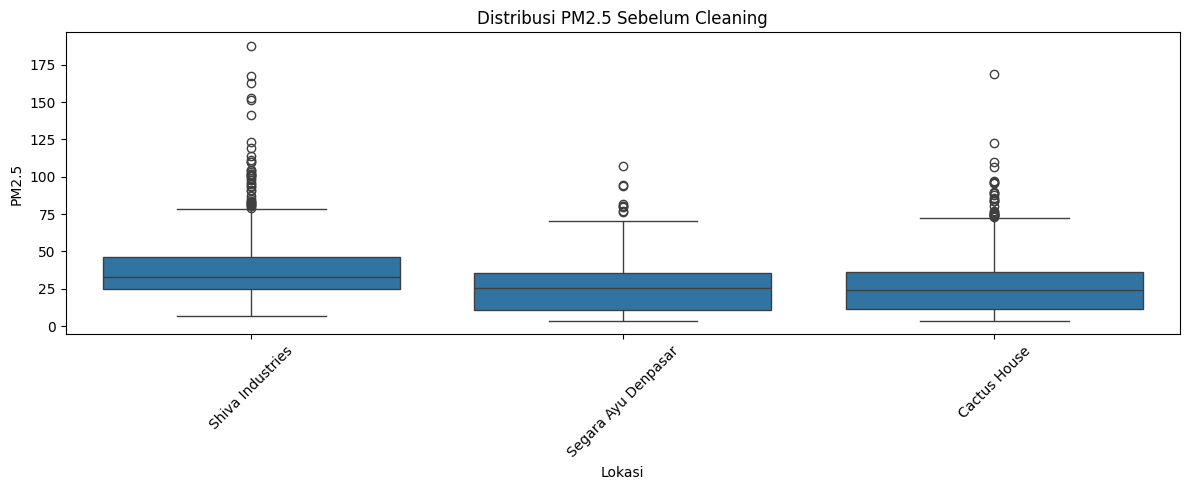

In [24]:
openaq_pm25_before = df_openaq[
    df_openaq["parameter_name"].str.lower() == "pm25"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=openaq_pm25_before,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi PM2.5 Sebelum Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("PM2.5")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
# Pastikan observed_at menjadi datetime
df_openaq_clean["observed_at"] = pd.to_datetime(
    df_openaq_clean["observed_at"],
    errors="coerce",
    utc=True
)

# Pastikan value numerik
df_openaq_clean["value"] = pd.to_numeric(
    df_openaq_clean["value"],
    errors="coerce"
)

# Hapus baris yang tidak memiliki informasi penting
df_openaq_clean = df_openaq_clean.dropna(
    subset=[
        "location_id",
        "observed_at",
        "value"
    ]
)

# Hapus duplicate berdasarkan identitas observasi
df_openaq_clean = df_openaq_clean.drop_duplicates(
    subset=[
        "location_id",
        "sensor_id",
        "parameter_name",
        "observed_at"
    ]
)

df_openaq_clean = df_openaq_clean.sort_values(
    [
        "location_id",
        "observed_at"
    ]
).reset_index(drop=True)

In [26]:
# VALIDASI HASIL CLEANING OPENAQ

print("Baris setelah cleaning:", len(df_openaq_clean))
print(
    "Timestamp tidak valid:",
    df_openaq_clean["observed_at"].isna().sum()
)
print(
    "Nilai PM2.5 kosong:",
    df_openaq_clean.loc[
        df_openaq_clean["parameter_name"]
        .astype(str).str.lower().eq("pm25"),
        "value"
    ].isna().sum()
)

print("\nJumlah data per parameter:")
display(
    df_openaq_clean["parameter_name"]
    .value_counts(dropna=False)
)

print("\nJumlah lokasi:")
print(df_openaq_clean["location_id"].nunique())

Baris setelah cleaning: 8035
Timestamp tidak valid: 0
Nilai PM2.5 kosong: 0

Jumlah data per parameter:


parameter_name
pm1                 1607
pm25                1607
relativehumidity    1607
temperature         1607
um003               1607
Name: count, dtype: int64


Jumlah lokasi:
3


In [27]:
print("Jumlah data setelah cleaning:")
print(f"Rows    : {len(df_openaq_clean):,}")
print(f"Columns : {len(df_openaq_clean.columns)}")

df_openaq_clean.head()

Jumlah data setelah cleaning:
Rows    : 8,035
Columns : 10


,location_id,location_name,latitude,longitude,sensor_id,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,17287509,19,pm1,12.4,µg/m³,2026-09-10 07:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,25.6,µg/m³,2026-09-10 07:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,17287511,98,relativehumidity,62.0,%,2026-09-10 07:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,17287512,100,temperature,27.8,c,2026-09-10 07:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,17287513,125,um003,861.0,particles/cm³,2026-09-10 07:00:00+00:00


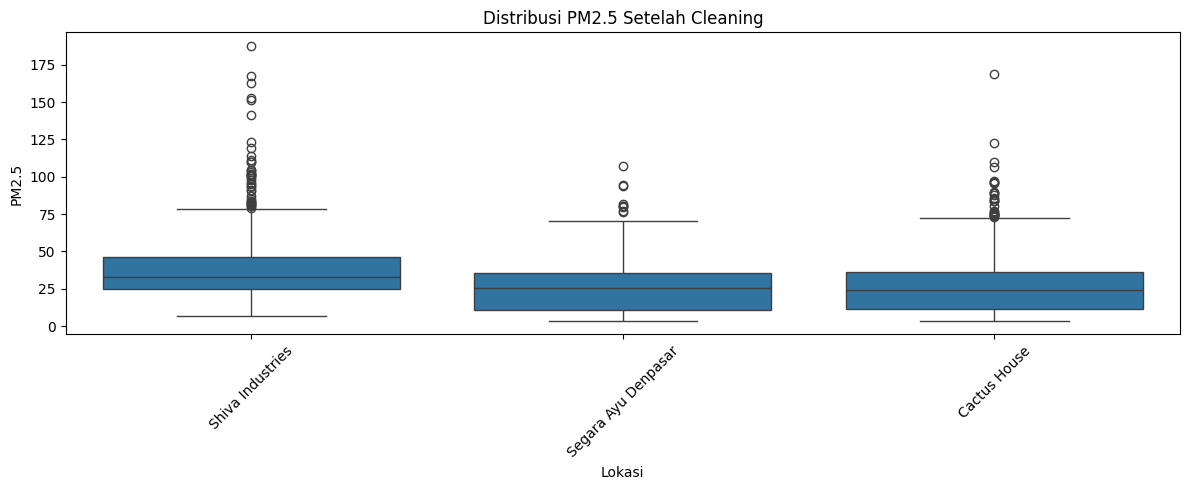

In [28]:
openaq_pm25_after = df_openaq_clean[
    df_openaq_clean["parameter_name"].str.lower() == "pm25"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=openaq_pm25_after,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi PM2.5 Setelah Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("PM2.5")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Open-Meteo

In [29]:
df_open_meteo_clean = df_open_meteo.copy()

print("Jumlah data sebelum cleaning:")
print(f"Rows    : {len(df_open_meteo_clean):,}")
print(f"Columns : {len(df_open_meteo_clean.columns)}")

Jumlah data sebelum cleaning:
Rows    : 10,800
Columns : 9


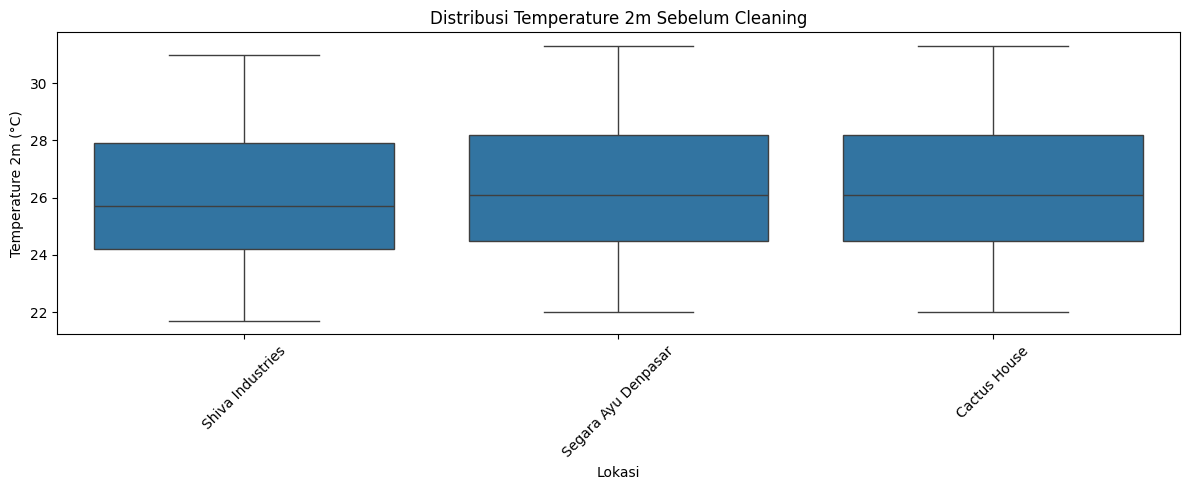

In [30]:
# ============================================================
# OPEN-METEO - SEBELUM CLEANING
# ============================================================

temperature_before = df_open_meteo[
    df_open_meteo["parameter_name"].str.lower()
    == "temperature_2m"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=temperature_before,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi Temperature 2m Sebelum Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("Temperature 2m (°C)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [31]:
df_open_meteo_clean["observed_at"] = pd.to_datetime(
    df_open_meteo_clean["observed_at"],
    errors="coerce",
    utc=True
)

df_open_meteo_clean["value"] = pd.to_numeric(
    df_open_meteo_clean["value"],
    errors="coerce"
)

df_open_meteo_clean = df_open_meteo_clean.dropna(
    subset=[
        "location_id",
        "parameter_name",
        "observed_at",
        "value"
    ]
)

df_open_meteo_clean = df_open_meteo_clean.drop_duplicates(
    subset=[
        "location_id",
        "parameter_name",
        "observed_at"
    ]
)

df_open_meteo_clean = df_open_meteo_clean.sort_values(
    [
        "location_id",
        "parameter_name",
        "observed_at"
    ]
).reset_index(drop=True)

In [32]:
# VALIDASI HASIL CLEANING OPEN-METEO

print("Baris setelah cleaning:", len(df_open_meteo_clean))
print(
    "Timestamp tidak valid:",
    df_open_meteo_clean["observed_at"].isna().sum()
)

print("\nJumlah observasi per parameter:")
display(
    df_open_meteo_clean.groupby("parameter_name").size()
)

print("\nDuplikasi berdasarkan lokasi, parameter, waktu:")
print(
    df_open_meteo_clean.duplicated(
        subset=[
            "location_id",
            "parameter_name",
            "observed_at"
        ]
    ).sum()
)

Baris setelah cleaning: 10800
Timestamp tidak valid: 0

Jumlah observasi per parameter:


parameter_name
precipitation           2160
relative_humidity_2m    2160
temperature_2m          2160
wind_direction_10m      2160
wind_speed_10m          2160
dtype: int64


Duplikasi berdasarkan lokasi, parameter, waktu:
0


In [33]:
print("Jumlah data setelah cleaning:")
print(f"Rows    : {len(df_open_meteo_clean):,}")
print(f"Columns : {len(df_open_meteo_clean.columns)}")

df_open_meteo_clean.head()

Jumlah data setelah cleaning:
Rows    : 10,800
Columns : 9


,location_id,location_name,latitude,longitude,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.3,mm,2026-09-07 02:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.3,mm,2026-09-07 03:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.2,mm,2026-09-07 04:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.1,mm,2026-09-07 05:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,precipitation,precipitation,0.2,mm,2026-09-07 06:00:00+00:00


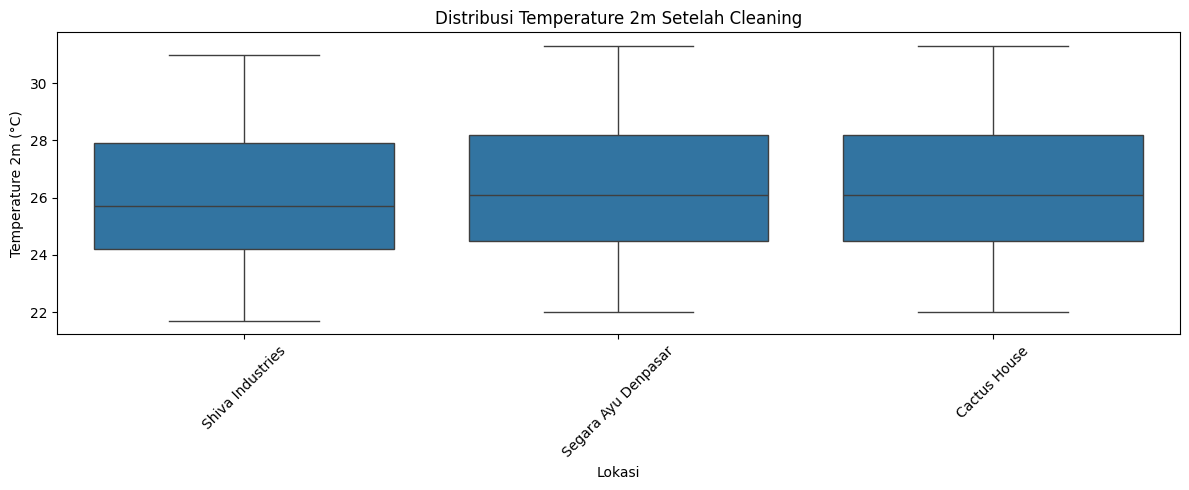

In [34]:
# ============================================================
# OPEN-METEO - SETELAH CLEANING
# ============================================================

temperature_after = df_open_meteo_clean[
    df_open_meteo_clean["parameter_name"].str.lower()
    == "temperature_2m"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=temperature_after,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi Temperature 2m Setelah Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("Temperature 2m (°C)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

NASA-POWER

In [35]:
df_nasa_power_clean = df_nasa_power.copy()

print("Jumlah data sebelum cleaning:")
print(f"Rows    : {len(df_nasa_power_clean):,}")
print(f"Columns : {len(df_nasa_power_clean.columns)}")

Jumlah data sebelum cleaning:
Rows    : 2,160
Columns : 9


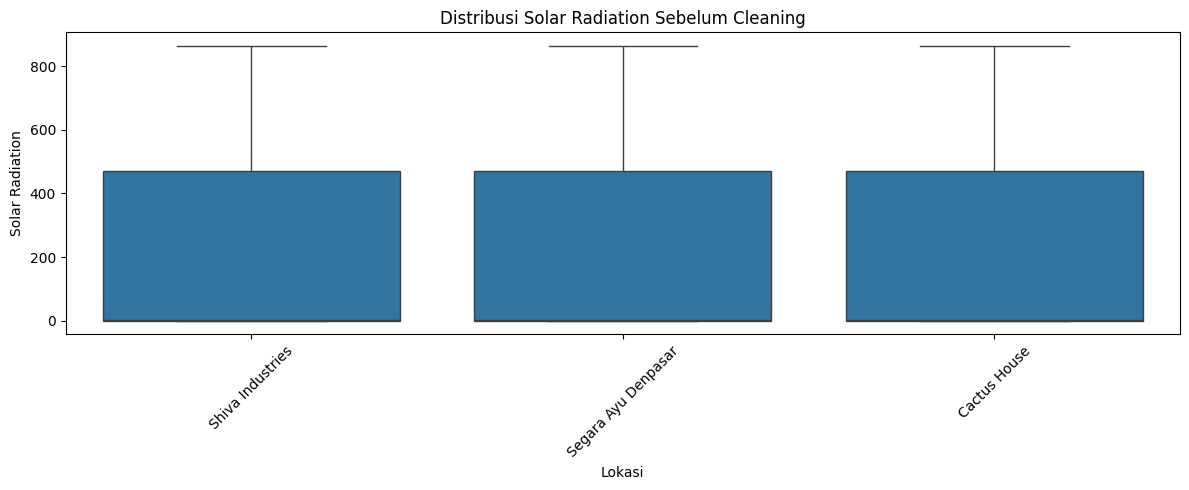

In [36]:
# ============================================================
# NASA POWER - SEBELUM CLEANING
# ============================================================

solar_before = df_nasa_power[
    df_nasa_power["parameter_name"].str.upper()
    == "ALLSKY_SFC_SW_DWN"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=solar_before,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi Solar Radiation Sebelum Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("Solar Radiation")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [37]:
df_nasa_power_clean["observed_at"] = pd.to_datetime(
    df_nasa_power_clean["observed_at"],
    errors="coerce",
    utc=True
)

df_nasa_power_clean["value"] = pd.to_numeric(
    df_nasa_power_clean["value"],
    errors="coerce"
)

df_nasa_power_clean = df_nasa_power_clean.dropna(
    subset=[
        "location_id",
        "parameter_name",
        "observed_at",
        "value"
    ]
)

df_nasa_power_clean = df_nasa_power_clean.drop_duplicates(
    subset=[
        "location_id",
        "parameter_name",
        "observed_at"
    ]
)

df_nasa_power_clean = df_nasa_power_clean.sort_values(
    [
        "location_id",
        "observed_at"
    ]
).reset_index(drop=True)

In [38]:
# VALIDASI HASIL CLEANING NASA POWER

print("Baris setelah cleaning:", len(df_nasa_power_clean))
print(
    "Timestamp tidak valid:",
    df_nasa_power_clean["observed_at"].isna().sum()
)

print("\nParameter yang tersedia:")
display(
    df_nasa_power_clean["parameter_name"]
    .value_counts(dropna=False)
)

print("\nJumlah data per lokasi:")
display(
    df_nasa_power_clean.groupby("location_id").size()
)

Baris setelah cleaning: 2160
Timestamp tidak valid: 0

Parameter yang tersedia:


parameter_name
ALLSKY_SFC_SW_DWN    2160
Name: count, dtype: int64


Jumlah data per lokasi:


location_id
6494341    720
6529627    720
6536246    720
dtype: int64

In [39]:
print("Jumlah data setelah cleaning:")
print(f"Rows    : {len(df_nasa_power_clean):,}")
print(f"Columns : {len(df_nasa_power_clean.columns)}")

df_nasa_power_clean.head()

Jumlah data setelah cleaning:
Rows    : 2,160
Columns : 9


,location_id,location_name,latitude,longitude,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,392.98,kWh/m2,2026-06-01 00:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,589.83,kWh/m2,2026-06-01 01:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,738.35,kWh/m2,2026-06-01 02:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,827.55,kWh/m2,2026-06-01 03:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,856.15,kWh/m2,2026-06-01 04:00:00+00:00


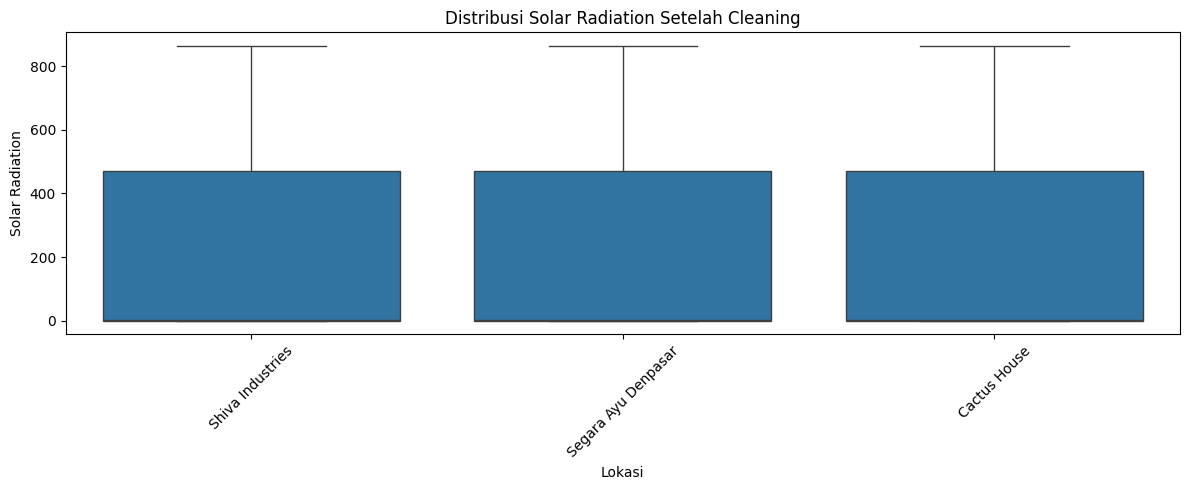

In [40]:
# ============================================================
# NASA POWER - SETELAH CLEANING
# ============================================================

solar_after = df_nasa_power_clean[
    df_nasa_power_clean["parameter_name"].str.upper()
    == "ALLSKY_SFC_SW_DWN"
].copy()

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=solar_after,
    x="location_name",
    y="value"
)

plt.title(
    "Distribusi Solar Radiation Setelah Cleaning"
)

plt.xlabel("Lokasi")
plt.ylabel("Solar Radiation")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Ringkasan Cleaning

In [41]:
# ============================================================
# CLEANING SUMMARY
# ============================================================

cleaning_summary = pd.DataFrame({
    "Dataset": [
        "OpenAQ",
        "Open-Meteo",
        "NASA POWER"
    ],

    "Before": [
        len(df_openaq),
        len(df_open_meteo),
        len(df_nasa_power)
    ],

    "After": [
        len(df_openaq_clean),
        len(df_open_meteo_clean),
        len(df_nasa_power_clean)
    ]
})

cleaning_summary["Removed"] = (
    cleaning_summary["Before"]
    - cleaning_summary["After"]
)

cleaning_summary

,Dataset,Before,After,Removed
0,OpenAQ,8035,8035,0
1,Open-Meteo,10800,10800,0
2,NASA POWER,2160,2160,0


## Exploratory Data Analysis

Pertanyaan
1. Bagaimana kondisi dan pola konsentrasi PM2.5 di beberapa lokasi pengamatan di Kota Denpasar selama periode analisis? (OpenAQ)

Tujuan
BQ1 menjadi analisis dasar untuk memahami:
- bagaimana distribusi PM2.5;
- lokasi mana yang memiliki konsentrasi rata-rata lebih tinggi;
- bagaimana PM2.5 berubah terhadap waktu;
- apakah terdapat pola berdasarkan jam.

Untuk BQ1 cukup menggunakan OpenAQ.

In [46]:
# Menyiapkan data PM2.5
df_openaq_clean["parameter_name"].value_counts()

df_pm25 = df_openaq_clean[
    df_openaq_clean["parameter_name"].str.lower() == "pm25"
].copy()

print(f"Jumlah data PM2.5: {len(df_pm25):,}")
df_pm25.head()

Jumlah data PM2.5: 1,607


,location_id,location_name,latitude,longitude,sensor_id,parameter_id,parameter_name,value,unit,observed_at
1,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,25.6,µg/m³,2026-09-10 07:00:00+00:00
6,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,28.6,µg/m³,2026-09-10 08:00:00+00:00
11,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,27.7,µg/m³,2026-09-10 09:00:00+00:00
16,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,37.0,µg/m³,2026-09-10 10:00:00+00:00
21,6494341,Shiva Industries,-8.641829,115.199421,17287510,2,pm25,37.3,µg/m³,2026-09-10 11:00:00+00:00


In [43]:
# Statistik PM2.5 berdasarkan lokasi
pm25_by_location = (
    df_pm25
    .groupby(
        ["location_id", "location_name"]
    )["value"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

pm25_by_location

,location_id,location_name,count,mean,median,std,minimum,maximum
0,6494341,Shiva Industries,642,38.826791,32.80,23.109513,6.5,187.5
1,6529627,Segara Ayu Denpasar,370,26.053514,25.55,17.547476,3.6,107.4
2,6536246,Cactus House,595,28.268571,24.10,21.136383,3.6,169.0


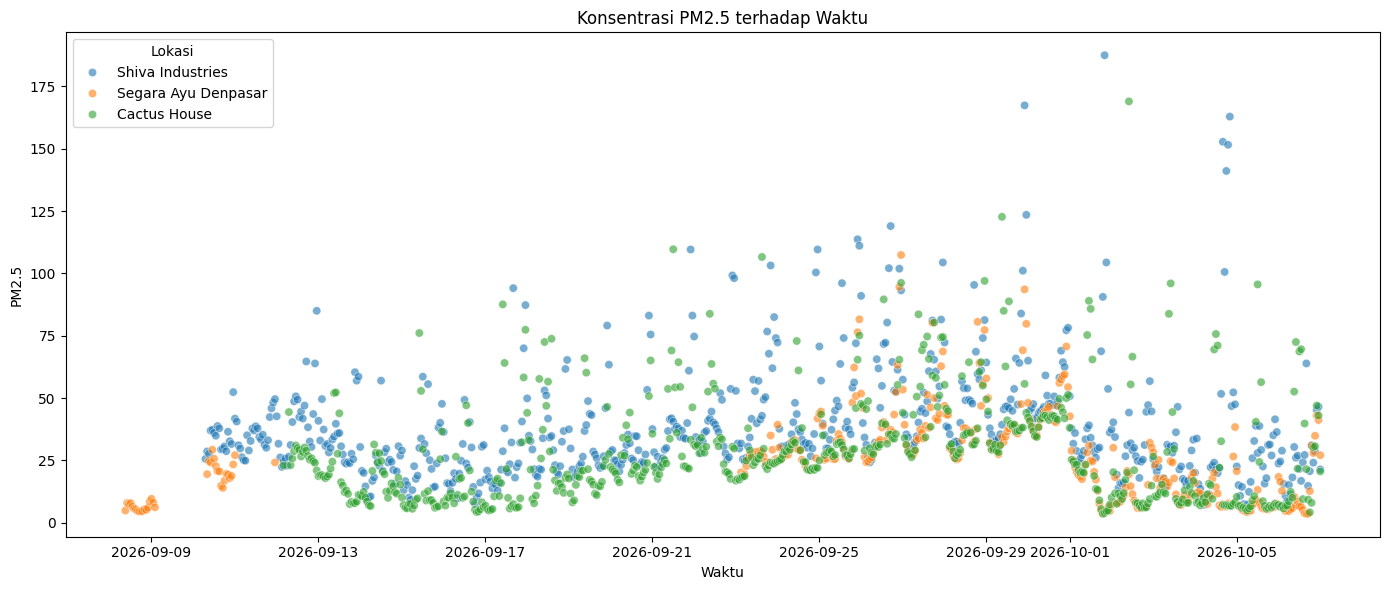

In [47]:
# Scatter plot PM2.5 terhadap waktu
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=df_pm25,
    x="observed_at",
    y="value",
    hue="location_name",
    alpha=0.6
)

plt.title("Konsentrasi PM2.5 terhadap Waktu")
plt.xlabel("Waktu")
plt.ylabel("PM2.5")
plt.legend(title="Lokasi")
plt.tight_layout()
plt.show()

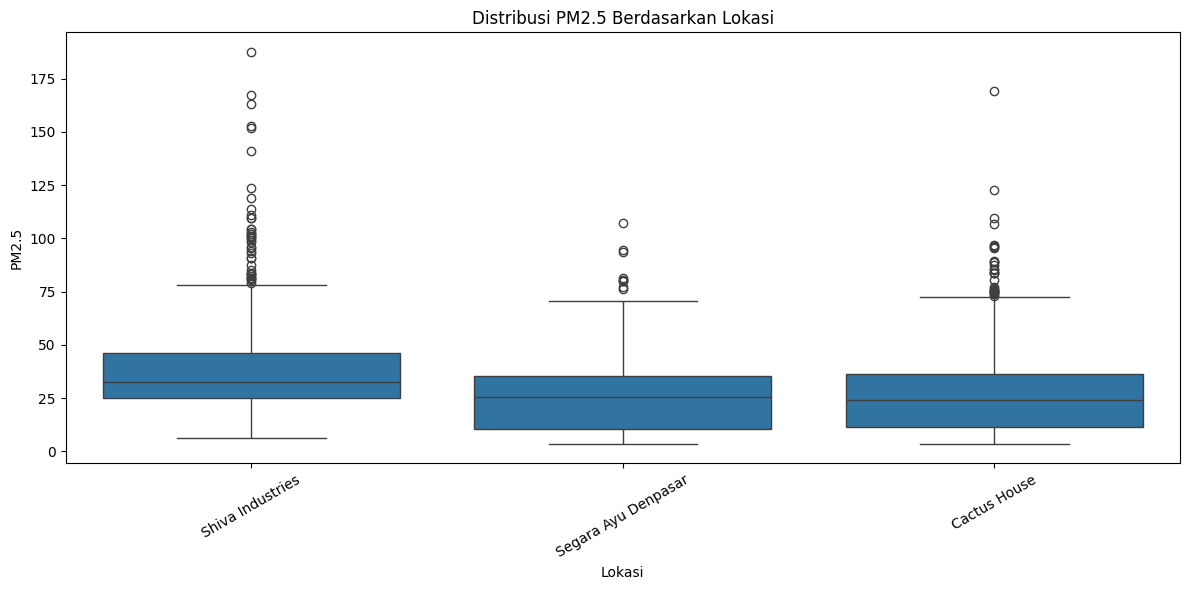

In [48]:
# Boxplot PM2.5 berdasarkan lokasi
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_pm25,
    x="location_name",
    y="value"
)

plt.title("Distribusi PM2.5 Berdasarkan Lokasi")
plt.xlabel("Lokasi")
plt.ylabel("PM2.5")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [72]:
# Analisis berdasarkan jam
df_pm25["observed_at_local"] = (
    df_pm25["observed_at"]
    .dt.tz_convert("Asia/Makassar")
)

df_pm25["hour"] = df_pm25["observed_at_local"].dt.hour

pm25_by_hour = (
    df_pm25
    .groupby(["location_name", "hour"])["value"]
    .mean()
    .reset_index()
)

pm25_by_hour.head()

,location_name,hour,value
0,Cactus House,0,21.936
1,Cactus House,1,19.676
2,Cactus House,2,20.348
3,Cactus House,3,19.448
4,Cactus House,4,21.144


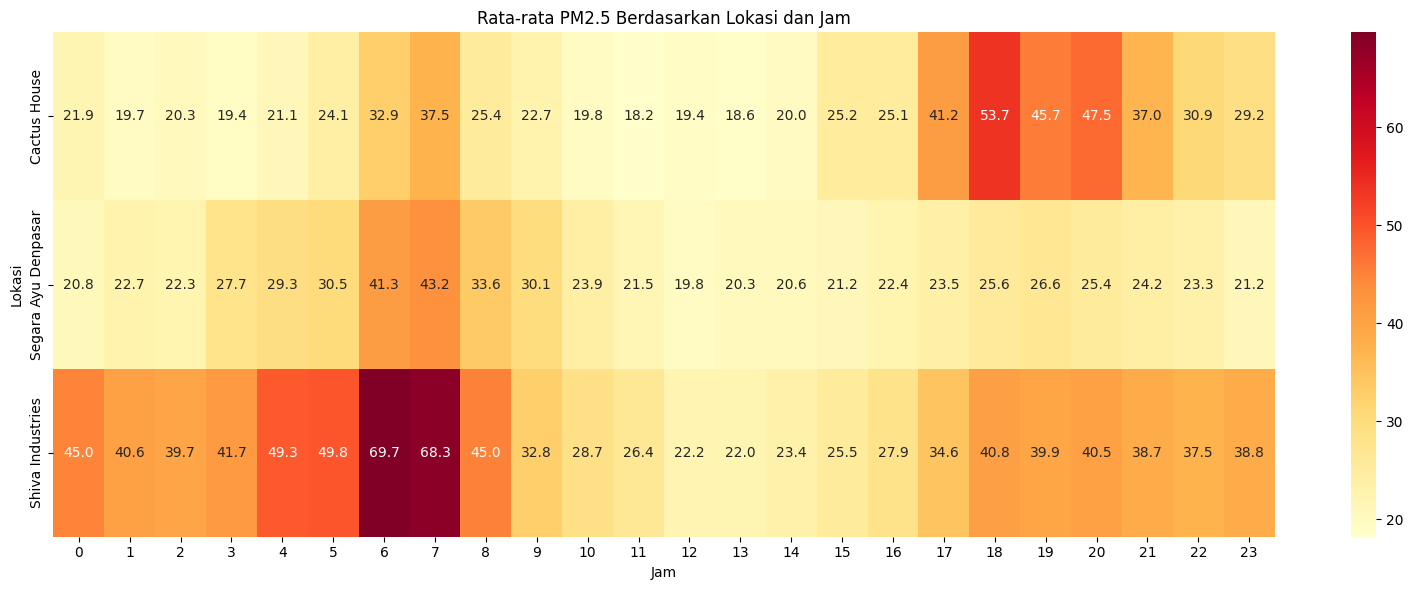

In [73]:
# Heatmap lokasi × jam
pm25_heatmap = pm25_by_hour.pivot(
    index="location_name",
    columns="hour",
    values="value"
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    pm25_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Rata-rata PM2.5 Berdasarkan Lokasi dan Jam")
plt.xlabel("Jam")
plt.ylabel("Lokasi")
plt.tight_layout()
plt.show()

Pertanyaan
2. Bagaimana hubungan antara kondisi meteorologis dan konsentrasi PM2.5 di Kota Denpasar?

Di sini baru kita membutuhkan:
- OpenAQ → PM2.5
- Open-Meteo → temperatur, kelembapan, hujan, angin

In [49]:
# Agregasikan PM2.5 menjadi hourly
df_pm25["observed_at_hour"] = (
    df_pm25["observed_at"].dt.floor("h")
)

df_pm25_hourly = (
    df_pm25
    .groupby(
        [
            "location_id",
            "location_name",
            "latitude",
            "longitude",
            "observed_at_hour"
        ],
        as_index=False
    )["value"]
    .mean()
    .rename(
        columns={
            "observed_at_hour": "observed_at",
            "value": "pm25"
        }
    )
)

In [50]:
# Periksa parameter Open-Meteo
df_open_meteo_clean["parameter_name"].value_counts()

df_meteo_wide = (
    df_open_meteo_clean
    .pivot_table(
        index=[
            "location_id",
            "observed_at"
        ],
        columns="parameter_name",
        values="value",
        aggfunc="mean"
    )
    .reset_index()
)

df_meteo_wide.columns.name = None

df_meteo_wide.head()

,location_id,observed_at,precipitation,relative_humidity_2m,temperature_2m,wind_direction_10m,wind_speed_10m
0,6494341,2026-09-07 02:00:00+00:00,0.3,75.0,26.1,130.0,10.7
1,6494341,2026-09-07 03:00:00+00:00,0.3,72.0,26.7,141.0,12.3
2,6494341,2026-09-07 04:00:00+00:00,0.2,69.0,27.3,146.0,14.3
3,6494341,2026-09-07 05:00:00+00:00,0.1,65.0,27.5,151.0,16.6
4,6494341,2026-09-07 06:00:00+00:00,0.2,63.0,27.8,141.0,17.3


In [51]:
# Gabungkan PM2.5 + meteorologi
df_bq2 = pd.merge(
    df_pm25_hourly,
    df_meteo_wide,
    on=["location_id", "observed_at"],
    how="inner"
)

print(f"Jumlah data BQ2: {len(df_bq2):,}")
print(df_bq2.columns.tolist())

df_bq2.head()

Jumlah data BQ2: 1,607
['location_id', 'location_name', 'latitude', 'longitude', 'observed_at', 'pm25', 'precipitation', 'relative_humidity_2m', 'temperature_2m', 'wind_direction_10m', 'wind_speed_10m']


,location_id,location_name,latitude,longitude,observed_at,pm25,precipitation,relative_humidity_2m,temperature_2m,wind_direction_10m,wind_speed_10m
0,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 07:00:00+00:00,25.6,0.0,68.0,27.5,139.0,20.2
1,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 08:00:00+00:00,28.6,0.0,70.0,26.9,138.0,20.0
2,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 09:00:00+00:00,27.7,0.0,72.0,26.3,137.0,19.1
3,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 10:00:00+00:00,37.0,0.0,74.0,25.7,135.0,17.9
4,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 11:00:00+00:00,37.3,0.0,78.0,25.4,133.0,15.0


In [52]:
df_bq2.isnull().sum()

location_id             0
location_name           0
latitude                0
longitude               0
observed_at             0
pm25                    0
precipitation           0
relative_humidity_2m    0
temperature_2m          0
wind_direction_10m      0
wind_speed_10m          0
dtype: int64

In [53]:
df_bq2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1607 entries, 0 to 1606
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   location_id           1607 non-null   int64              
 1   location_name         1607 non-null   object             
 2   latitude              1607 non-null   float64            
 3   longitude             1607 non-null   float64            
 4   observed_at           1607 non-null   datetime64[ns, UTC]
 5   pm25                  1607 non-null   float64            
 6   precipitation         1607 non-null   float64            
 7   relative_humidity_2m  1607 non-null   float64            
 8   temperature_2m        1607 non-null   float64            
 9   wind_direction_10m    1607 non-null   float64            
 10  wind_speed_10m        1607 non-null   float64            
dtypes: datetime64[ns, UTC](1), float64(8), int64(1), object(1)
memory usa

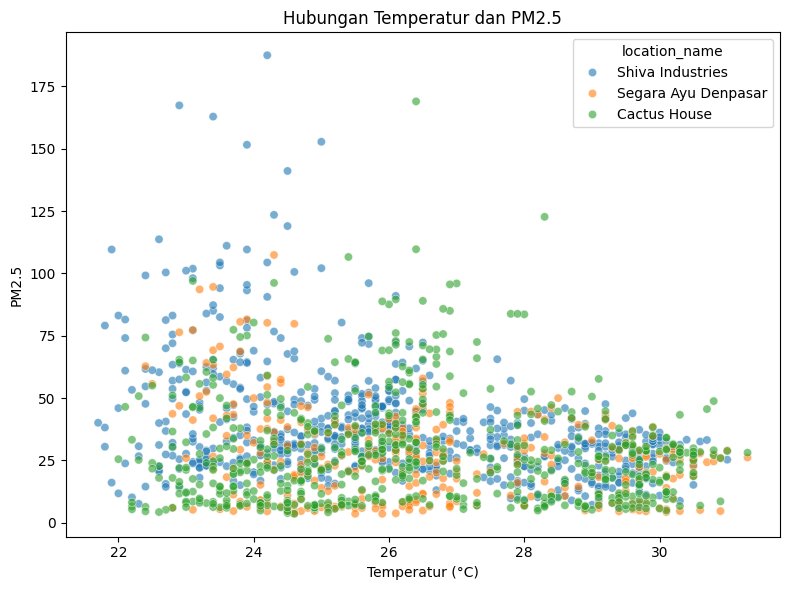

In [54]:
# Scatter plot PM2.5 vs temperatur
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_bq2,
    x="temperature_2m",
    y="pm25",
    hue="location_name",
    alpha=0.6
)

plt.title("Hubungan Temperatur dan PM2.5")
plt.xlabel("Temperatur (°C)")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

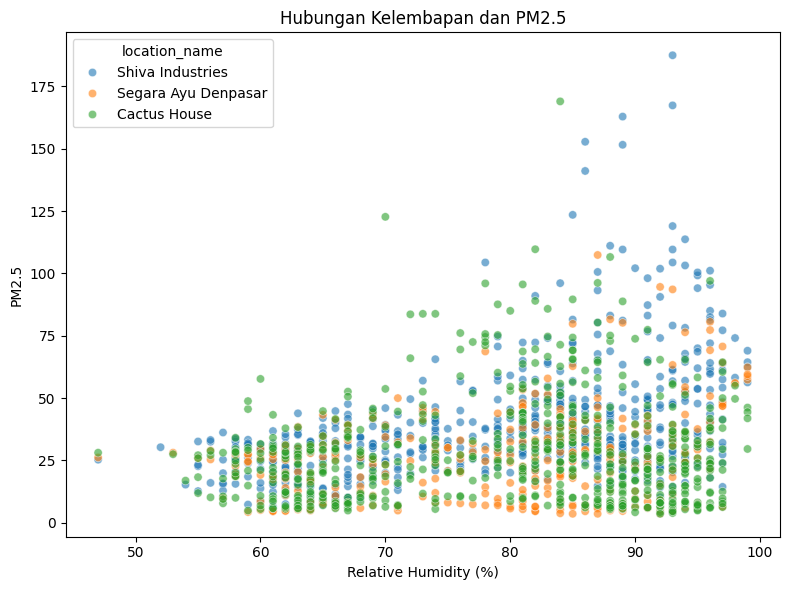

In [55]:
# Scatter plot PM2.5 vs kelembapan
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_bq2,
    x="relative_humidity_2m",
    y="pm25",
    hue="location_name",
    alpha=0.6
)

plt.title("Hubungan Kelembapan dan PM2.5")
plt.xlabel("Relative Humidity (%)")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

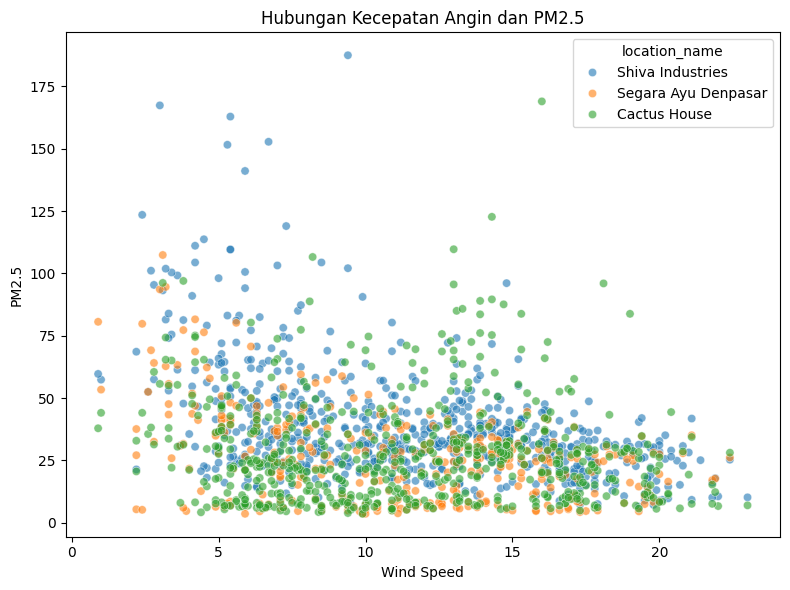

In [56]:
# Scatter plot PM2.5 vs kecepatan angin
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_bq2,
    x="wind_speed_10m",
    y="pm25",
    hue="location_name",
    alpha=0.6
)

plt.title("Hubungan Kecepatan Angin dan PM2.5")
plt.xlabel("Wind Speed")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

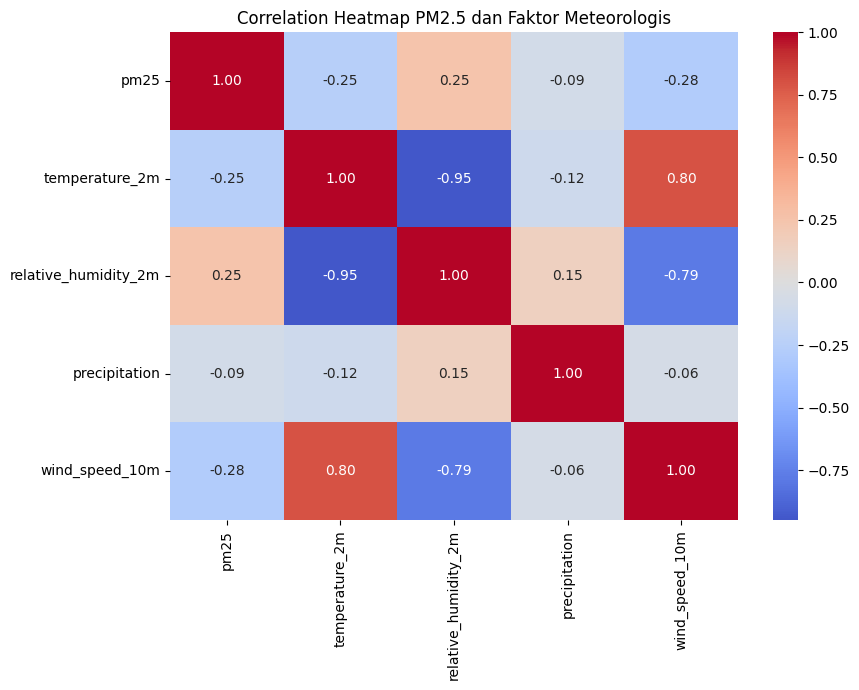

In [57]:
# Correlation heatmap
corr_columns = [
    "pm25",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m"
]

corr_matrix = df_bq2[corr_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap PM2.5 dan Faktor Meteorologis")
plt.tight_layout()
plt.show()

Pertanyaan
3. Pada lokasi pengamatan mana konsentrasi PM2.5 cenderung lebih tinggi, dan bagaimana karakteristik lingkungan berdasarkan data NASA POWER pada masing-masing lokasi?

BQ3 lebih lengkap karena sekarang kita tambahkan:
- OpenAQ
- Open-Meteo
- NASA POWER

NASA POWER digunakan sebagai faktor lingkungan tambahan, yaitu radiasi matahari.

In [58]:
# Siapkan data NASA POWER
df_nasa_power = pd.read_csv(
    DATA_DIR / "denpasar_nasa_power.csv"
)

df_nasa_power["observed_at"] = pd.to_datetime(
    df_nasa_power["observed_at"],
    utc=True
)

print("Shape NASA POWER:", df_nasa_power.shape)
display(df_nasa_power.head())

print(df_nasa_power["parameter_name"].unique())

Shape NASA POWER: (2160, 9)


,location_id,location_name,latitude,longitude,parameter_id,parameter_name,value,unit,observed_at
0,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,392.98,kWh/m2,2026-06-01 00:00:00+00:00
1,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,589.83,kWh/m2,2026-06-01 01:00:00+00:00
2,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,738.35,kWh/m2,2026-06-01 02:00:00+00:00
3,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,827.55,kWh/m2,2026-06-01 03:00:00+00:00
4,6494341,Shiva Industries,-8.641829,115.199421,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DWN,856.15,kWh/m2,2026-06-01 04:00:00+00:00


['ALLSKY_SFC_SW_DWN']


In [59]:
# Bersihkan NASA POWER
df_nasa_clean = df_nasa_power.copy()

df_nasa_clean["parameter_name"] = (
    df_nasa_clean["parameter_name"]
    .astype(str)
    .str.upper()
)

df_nasa_clean["value"] = pd.to_numeric(
    df_nasa_clean["value"],
    errors="coerce"
)

# Hanya parameter solar radiation
df_nasa_clean = df_nasa_clean[
    df_nasa_clean["parameter_name"] == "ALLSKY_SFC_SW_DWN"
].copy()

# Hapus nilai tidak valid
df_nasa_clean = df_nasa_clean[
    df_nasa_clean["value"].notna()
].copy()

print("Shape NASA setelah cleaning:", df_nasa_clean.shape)

display(
    df_nasa_clean[
        ["location_id", "observed_at", "parameter_name", "value"]
    ].head()
)

Shape NASA setelah cleaning: (2160, 9)


,location_id,observed_at,parameter_name,value
0,6494341,2026-06-01 00:00:00+00:00,ALLSKY_SFC_SW_DWN,392.98
1,6494341,2026-06-01 01:00:00+00:00,ALLSKY_SFC_SW_DWN,589.83
2,6494341,2026-06-01 02:00:00+00:00,ALLSKY_SFC_SW_DWN,738.35
3,6494341,2026-06-01 03:00:00+00:00,ALLSKY_SFC_SW_DWN,827.55
4,6494341,2026-06-01 04:00:00+00:00,ALLSKY_SFC_SW_DWN,856.15


In [63]:
# ============================================================
# AUDIT NASA POWER PER LOKASI DAN WAKTU
# ============================================================

df_nasa_clean["observed_at"] = pd.to_datetime(
    df_nasa_clean["observed_at"],
    errors="coerce",
    utc=True
)

df_nasa_clean["value"] = pd.to_numeric(
    df_nasa_clean["value"],
    errors="coerce"
)

df_nasa_clean = df_nasa_clean.dropna(
    subset=["location_id", "observed_at", "value"]
).copy()

print("Parameter NASA POWER:")
display(
    df_nasa_clean["parameter_name"].value_counts()
)

solar_data = df_nasa_clean[
    df_nasa_clean["parameter_name"]
    .astype(str)
    .str.upper()
    .eq("ALLSKY_SFC_SW_DWN")
].copy()

if solar_data.empty:
    raise ValueError(
        "Tidak ada data ALLSKY_SFC_SW_DWN. "
        "Periksa nama parameter dalam CSV NASA POWER."
    )

print("Jumlah baris solar:", len(solar_data))
print("Jumlah lokasi:", solar_data["location_id"].nunique())

# Statistik nilai per lokasi
solar_audit = (
    solar_data
    .groupby("location_id")
    .agg(
        jumlah_data=("value", "count"),
        jumlah_waktu=("observed_at", "nunique"),
        jumlah_nilai_unik=("value", "nunique"),
        nilai_min=("value", "min"),
        nilai_median=("value", "median"),
        nilai_mean=("value", "mean"),
        nilai_std=("value", "std"),
        nilai_max=("value", "max"),
    )
    .reset_index()
)

display(solar_audit)

Parameter NASA POWER:


parameter_name
ALLSKY_SFC_SW_DWN    2160
Name: count, dtype: int64

Jumlah baris solar: 2160
Jumlah lokasi: 3


,location_id,jumlah_data,jumlah_waktu,jumlah_nilai_unik,nilai_min,nilai_median,nilai_mean,nilai_std,nilai_max
0,6494341,720,720,356,0.0,2.69,218.2575,289.55276,862.83
1,6529627,720,720,356,0.0,2.69,218.2575,289.55276,862.83
2,6536246,720,720,356,0.0,2.69,218.2575,289.55276,862.83


Audit ini membantu memastikan jumlah pengukuran dan variasi nilai radiasi matahari. Jangan langsung menyimpulkan bahwa data NASA POWER salah hanya karena nilai ringkasannya terlihat tidak biasa. Periksa dulu satuan, rentang waktu, frekuensi pengukuran, dan dokumentasi parameter sumbernya.

In [70]:
# Periksa contoh data berdasarkan waktu
display(
    solar_data[
        ["location_id", "observed_at", "value"]
    ]
    .sort_values(["location_id", "observed_at"])
    .head(30)
)

,location_id,observed_at,value
0,6494341,2026-06-01 00:00:00+00:00,392.98
1,6494341,2026-06-01 01:00:00+00:00,589.83
2,6494341,2026-06-01 02:00:00+00:00,738.35
3,6494341,2026-06-01 03:00:00+00:00,827.55
4,6494341,2026-06-01 04:00:00+00:00,856.15
5,6494341,2026-06-01 05:00:00+00:00,799.33
6,6494341,2026-06-01 06:00:00+00:00,676.97
7,6494341,2026-06-01 07:00:00+00:00,494.75
8,6494341,2026-06-01 08:00:00+00:00,273.67
9,6494341,2026-06-01 09:00:00+00:00,67.35


In [71]:
# ============================================================
# BQ3 - SEL 65
# AUDIT RENTANG WAKTU DAN GABUNGKAN RINGKASAN PER LOKASI
# ============================================================

nasa_location_summary = (
    solar_data
    .groupby("location_id")["value"]
    .agg(
        solar_mean="mean",
        solar_median="median",
        solar_std="std",
        solar_min="min",
        solar_max="max"
    )
    .reset_index()
)

# Pastikan timestamp memiliki format datetime
df_bq2["observed_at"] = pd.to_datetime(
    df_bq2["observed_at"], utc=True, errors="coerce"
)
df_nasa_clean["observed_at"] = pd.to_datetime(
    df_nasa_clean["observed_at"], utc=True, errors="coerce"
)

print("Rentang waktu PM2.5:")
print(df_bq2["observed_at"].min(), "sampai", df_bq2["observed_at"].max())

print("\nRentang waktu NASA POWER:")
print(
    df_nasa_clean["observed_at"].min(),
    "sampai",
    df_nasa_clean["observed_at"].max()
)

# Periksa apakah rentang waktunya saling bertumpang tindih
pm_start = df_bq2["observed_at"].min()
pm_end = df_bq2["observed_at"].max()
nasa_start = df_nasa_clean["observed_at"].min()
nasa_end = df_nasa_clean["observed_at"].max()

overlap = (
    pd.notna(pm_start)
    and pd.notna(pm_end)
    and pd.notna(nasa_start)
    and pd.notna(nasa_end)
    and max(pm_start, nasa_start) <= min(pm_end, nasa_end)
)

print("\nApakah rentang waktu kedua dataset bertumpang tindih?", overlap)

# Gabungkan ringkasan NASA per lokasi dengan data BQ2.
# Ini untuk tabel deskriptif per lokasi, bukan pencocokan per jam.
df_bq3 = pd.merge(
    df_bq2,
    nasa_location_summary,
    on="location_id",
    how="left",
    validate="many_to_one"
)

print("\nShape BQ3:", df_bq3.shape)
print("Jumlah lokasi:", df_bq3["location_id"].nunique())

display(df_bq3.head())

print("\nMissing value:")
display(df_bq3.isnull().sum())

Rentang waktu PM2.5:
2026-09-08 09:00:00+00:00 sampai 2026-10-07 00:00:00+00:00

Rentang waktu NASA POWER:
2026-06-01 00:00:00+00:00 sampai 2026-06-30 23:00:00+00:00

Apakah rentang waktu kedua dataset bertumpang tindih? False

Shape BQ3: (1607, 16)
Jumlah lokasi: 3


,location_id,location_name,latitude,longitude,observed_at,pm25,precipitation,relative_humidity_2m,temperature_2m,wind_direction_10m,wind_speed_10m,solar_mean,solar_median,solar_std,solar_min,solar_max
0,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 07:00:00+00:00,25.6,0.0,68.0,27.5,139.0,20.2,218.2575,2.69,289.55276,0.0,862.83
1,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 08:00:00+00:00,28.6,0.0,70.0,26.9,138.0,20.0,218.2575,2.69,289.55276,0.0,862.83
2,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 09:00:00+00:00,27.7,0.0,72.0,26.3,137.0,19.1,218.2575,2.69,289.55276,0.0,862.83
3,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 10:00:00+00:00,37.0,0.0,74.0,25.7,135.0,17.9,218.2575,2.69,289.55276,0.0,862.83
4,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 11:00:00+00:00,37.3,0.0,78.0,25.4,133.0,15.0,218.2575,2.69,289.55276,0.0,862.83



Missing value:


location_id             0
location_name           0
latitude                0
longitude               0
observed_at             0
pm25                    0
precipitation           0
relative_humidity_2m    0
temperature_2m          0
wind_direction_10m      0
wind_speed_10m          0
solar_mean              0
solar_median            0
solar_std               0
solar_min               0
solar_max               0
dtype: int64

In [72]:
# ============================================================
# BQ3 - SEL 66
# RINGKASAN PM2.5 DAN NASA POWER PER LOKASI
# ============================================================

# Ringkasan PM2.5 dari data pengamatan
pm25_location_bq3 = (
    df_bq2
    .groupby(
        ["location_id", "location_name"],
        as_index=False
    )
    .agg(
        pm25_mean=("pm25", "mean"),
        pm25_median=("pm25", "median"),
        pm25_std=("pm25", "std"),
        pm25_min=("pm25", "min"),
        pm25_max=("pm25", "max"),
        jumlah_observasi=("pm25", "count")
    )
)

# Tambahkan ringkasan NASA POWER berdasarkan lokasi
pm25_location_bq3 = pm25_location_bq3.merge(
    nasa_location_summary,
    on="location_id",
    how="left",
    validate="one_to_one"
)

pm25_location_bq3 = pm25_location_bq3.sort_values(
    "pm25_mean",
    ascending=False
).reset_index(drop=True)

print("Ringkasan PM2.5 dan NASA POWER per lokasi:")
display(pm25_location_bq3)

print("\nLokasi dengan rata-rata PM2.5 tertinggi:")
display(pm25_location_bq3.head(1))

print("\nPerbandingan karakteristik NASA POWER:")
display(
    nasa_location_summary.sort_values(
        "solar_mean", ascending=False
    )
)


Ringkasan PM2.5 dan NASA POWER per lokasi:


,location_id,location_name,pm25_mean,pm25_median,pm25_std,pm25_min,pm25_max,jumlah_observasi,solar_mean,solar_median,solar_std,solar_min,solar_max
0,6494341,Shiva Industries,38.826791,32.80,23.109513,6.5,187.5,642,218.2575,2.69,289.55276,0.0,862.83
1,6536246,Cactus House,28.268571,24.10,21.136383,3.6,169.0,595,218.2575,2.69,289.55276,0.0,862.83
2,6529627,Segara Ayu Denpasar,26.053514,25.55,17.547476,3.6,107.4,370,218.2575,2.69,289.55276,0.0,862.83



Lokasi dengan rata-rata PM2.5 tertinggi:


,location_id,location_name,pm25_mean,pm25_median,pm25_std,pm25_min,pm25_max,jumlah_observasi,solar_mean,solar_median,solar_std,solar_min,solar_max
0,6494341,Shiva Industries,38.826791,32.8,23.109513,6.5,187.5,642,218.2575,2.69,289.55276,0.0,862.83



Perbandingan karakteristik NASA POWER:


,location_id,solar_mean,solar_median,solar_std,solar_min,solar_max
0,6494341,218.2575,2.69,289.55276,0.0,862.83
1,6529627,218.2575,2.69,289.55276,0.0,862.83
2,6536246,218.2575,2.69,289.55276,0.0,862.83


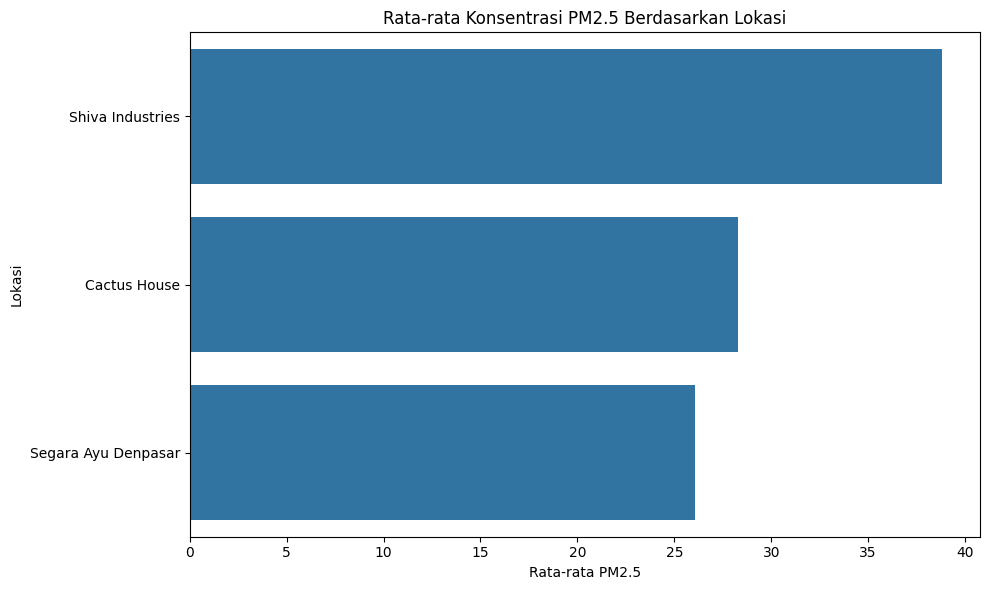

In [73]:
# ============================================================
# BQ3 - SEL 67
# GRAFIK RATA-RATA PM2.5 PER LOKASI
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=pm25_location_bq3,
    x="pm25_mean",
    y="location_name"
)

plt.title("Rata-rata Konsentrasi PM2.5 Berdasarkan Lokasi")
plt.xlabel("Rata-rata PM2.5")
plt.ylabel("Lokasi")
plt.tight_layout()
plt.show()

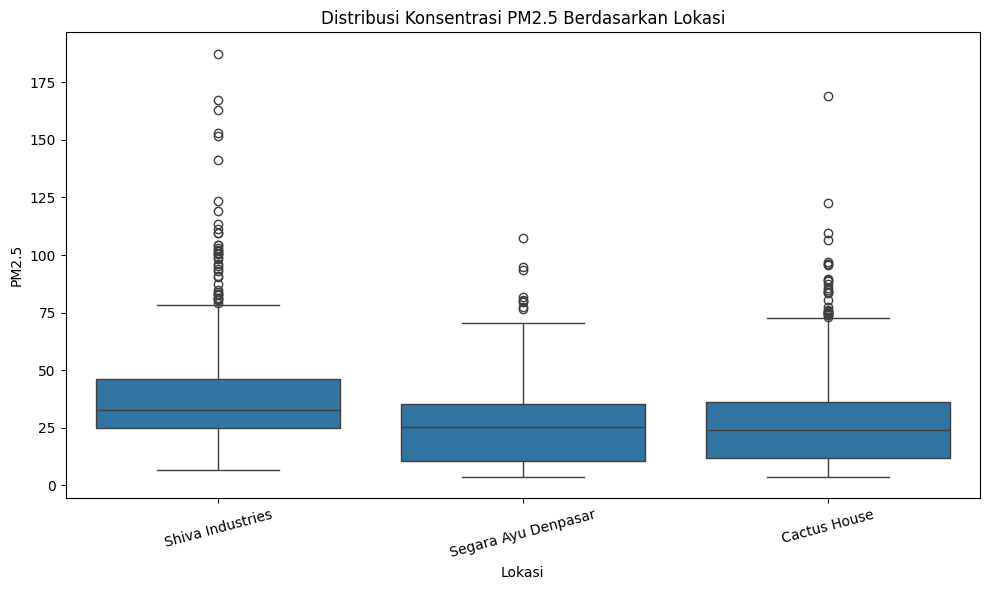

In [74]:

# ============================================================
# BQ3 - SEL 68
# DISTRIBUSI PM2.5 PER LOKASI
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_bq2,
    x="location_name",
    y="pm25"
)

plt.title("Distribusi Konsentrasi PM2.5 Berdasarkan Lokasi")
plt.xlabel("Lokasi")
plt.ylabel("PM2.5")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

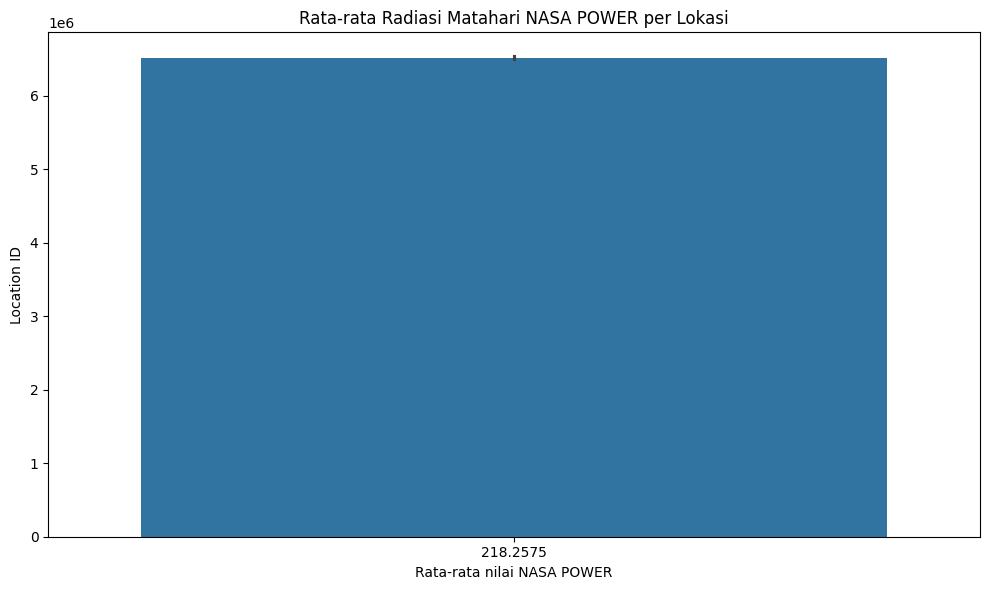

PERHATIAN: solar_mean sama pada seluruh lokasi. Grafik ini tidak menunjukkan perbedaan radiasi matahari antar lokasi pada data yang tersedia.


In [75]:

# ============================================================
# BQ3 - SEL 69
# RATA-RATA SOLAR RADIATION NASA POWER PER LOKASI
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=nasa_location_summary,
    x="solar_mean",
    y="location_id"
)

plt.title("Rata-rata Radiasi Matahari NASA POWER per Lokasi")
plt.xlabel("Rata-rata nilai NASA POWER")
plt.ylabel("Location ID")
plt.tight_layout()
plt.show()

# Periksa apakah nilai ringkasan berbeda antar lokasi
n_unique_solar = nasa_location_summary["solar_mean"].nunique()

if n_unique_solar <= 1:
    print(
        "PERHATIAN: solar_mean sama pada seluruh lokasi. "
        "Grafik ini tidak menunjukkan perbedaan radiasi matahari "
        "antar lokasi pada data yang tersedia."
    )

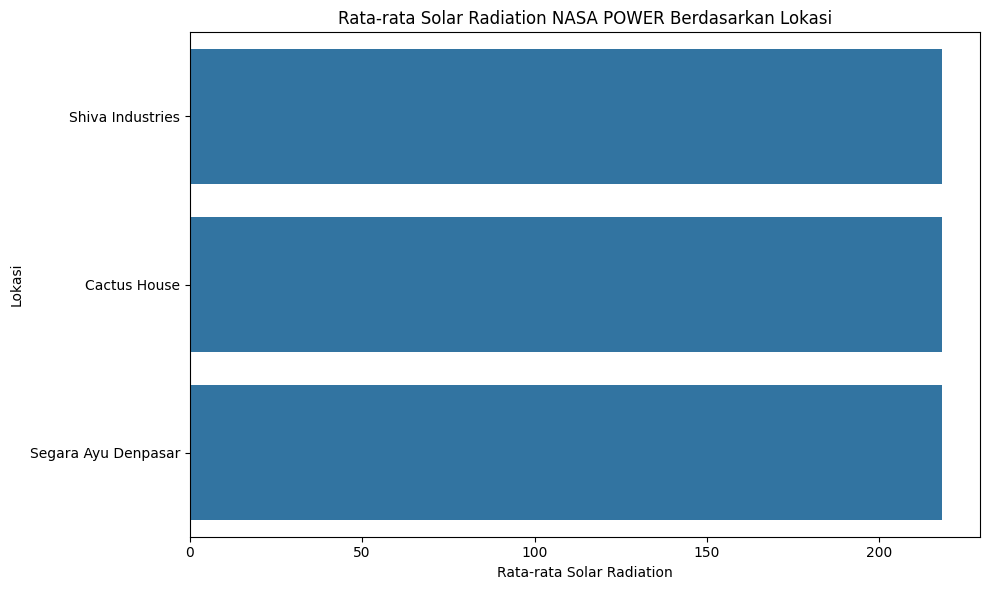

In [82]:
# Bandingkan karakteristik solar radiation NASA antar lokasi
plt.figure(figsize=(10, 6))

sns.barplot(
    data=pm25_location_bq3,
    x="solar_mean",
    y="location_name"
)

plt.title(
    "Rata-rata Solar Radiation NASA POWER Berdasarkan Lokasi"
)
plt.xlabel("Rata-rata Solar Radiation")
plt.ylabel("Lokasi")
plt.tight_layout()
plt.show()

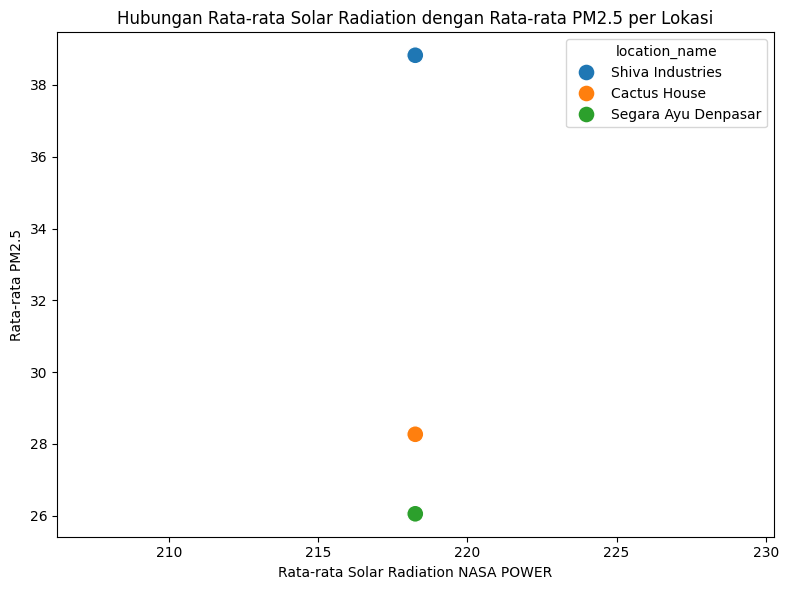

In [83]:
# Hubungan karakteristik solar radiation dengan PM2.5
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pm25_location_bq3,
    x="solar_mean",
    y="pm25_mean",
    hue="location_name",
    s=150
)

plt.title(
    "Hubungan Rata-rata Solar Radiation dengan Rata-rata PM2.5 per Lokasi"
)
plt.xlabel("Rata-rata Solar Radiation NASA POWER")
plt.ylabel("Rata-rata PM2.5")
plt.tight_layout()
plt.show()

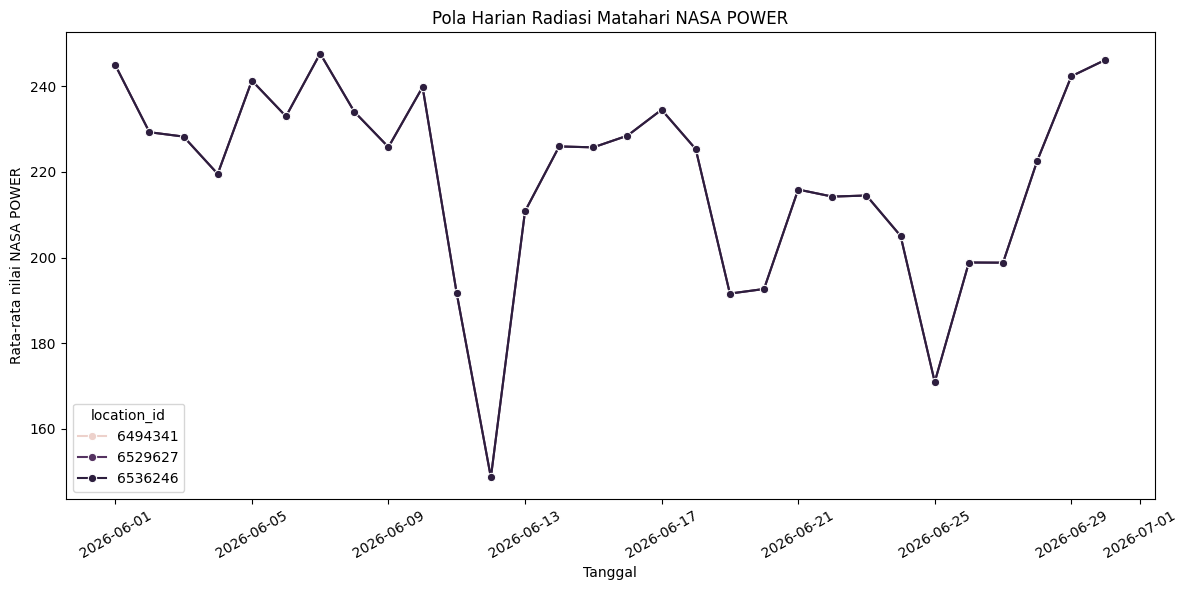

Jumlah baris NASA POWER per lokasi:


,location_id,jumlah_observasi
0,6494341,720
1,6529627,720
2,6536246,720


In [ ]:
# ============================================================
# BQ3 - SEL 70
# POLA RADIASI MATAHARI NASA POWER SEPANJANG WAKTU
# ============================================================

nasa_timeseries = df_nasa_clean.copy()

nasa_timeseries["tanggal"] = (
    nasa_timeseries["observed_at"].dt.date
)

nasa_daily = (
    nasa_timeseries
    .groupby(["location_id", "tanggal"], as_index=False)
    .agg(
        solar_mean=("value", "mean"),
        jumlah_observasi=("value", "count")
    )
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=nasa_daily,
    x="tanggal",
    y="solar_mean",
    hue="location_id",
    marker="o"
)

plt.title("Pola Harian Radiasi Matahari NASA POWER")
plt.xlabel("Tanggal")
plt.ylabel("Rata-rata nilai NASA POWER")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Jumlah baris NASA POWER per lokasi:")
display(
    df_nasa_clean.groupby("location_id")
    .size()
    .reset_index(name="jumlah_observasi")
)

In [84]:
# Membuat fitur waktu lokal WITA
df_bq3["observed_at"] = pd.to_datetime(
    df_bq3["observed_at"],
    utc=True
)

df_bq3["observed_at_wita"] = (
    df_bq3["observed_at"]
    .dt.tz_convert("Asia/Makassar")
)

df_bq3["hour"] = df_bq3["observed_at_wita"].dt.hour

print(df_bq3[
    ["location_name", "observed_at", "observed_at_wita", "hour", "pm25"]
].head())

      location_name               observed_at          observed_at_wita  hour  \
0  Shiva Industries 2026-09-10 07:00:00+00:00 2026-09-10 15:00:00+08:00    15   
1  Shiva Industries 2026-09-10 08:00:00+00:00 2026-09-10 16:00:00+08:00    16   
2  Shiva Industries 2026-09-10 09:00:00+00:00 2026-09-10 17:00:00+08:00    17   
3  Shiva Industries 2026-09-10 10:00:00+00:00 2026-09-10 18:00:00+08:00    18   
4  Shiva Industries 2026-09-10 11:00:00+00:00 2026-09-10 19:00:00+08:00    19   

   pm25  
0  25.6  
1  28.6  
2  27.7  
3  37.0  
4  37.3  


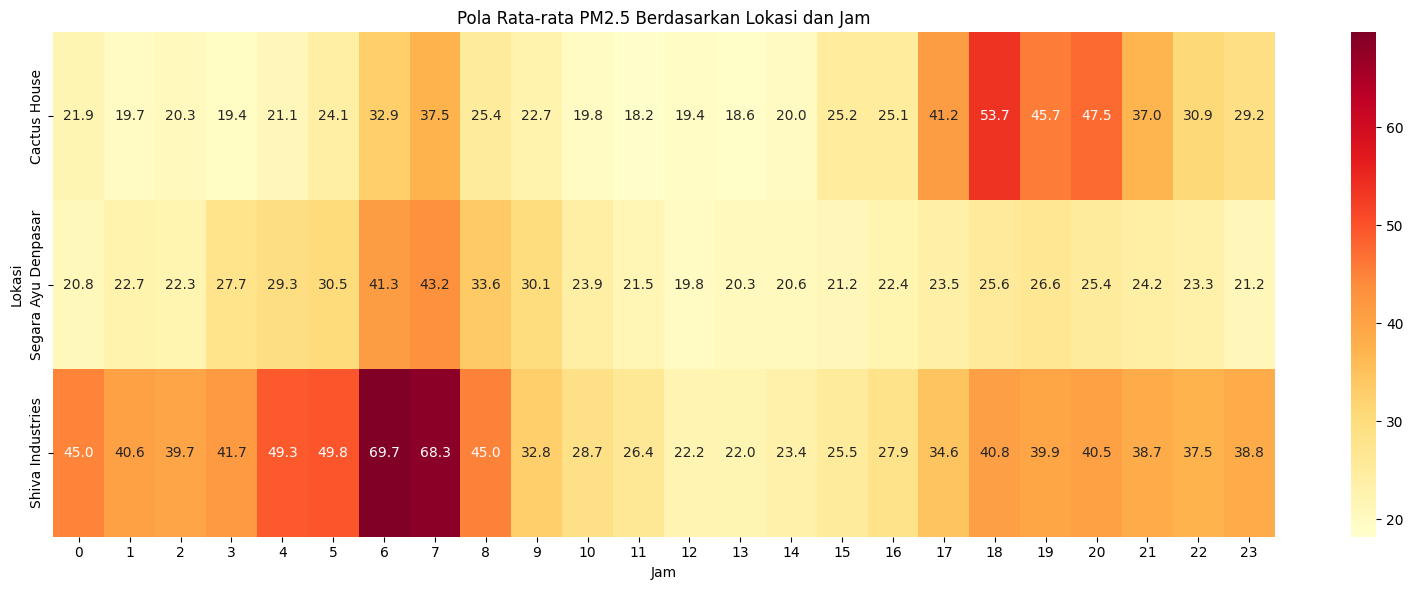

In [85]:
# Heatmap PM2.5 berdasarkan lokasi dan jam
pm25_hour_location_bq3 = (
    df_bq3
    .dropna(subset=["location_name", "hour", "pm25"])
    .groupby(
        ["location_name", "hour"]
    )["pm25"]
    .mean()
    .reset_index()
)

heatmap_bq3 = pm25_hour_location_bq3.pivot(
    index="location_name",
    columns="hour",
    values="pm25"
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_bq3,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title(
    "Pola Rata-rata PM2.5 Berdasarkan Lokasi dan Jam"
)
plt.xlabel("Jam")
plt.ylabel("Lokasi")
plt.tight_layout()
plt.show()

In [86]:

# ============================================================
# BQ3 - SEL 72
# AUDIT DAN RINGKASAN HASIL
# ============================================================

print("=" * 60)
print("RINGKASAN BUSINESS QUESTION 3")
print("=" * 60)

# 1. Peringkat lokasi berdasarkan PM2.5
print("\n1. Peringkat rata-rata PM2.5:")
display(
    pm25_location_bq3[
        [
            "location_name",
            "pm25_mean",
            "pm25_median",
            "pm25_std",
            "jumlah_observasi"
        ]
    ]
)

if not pm25_location_bq3.empty:
    tertinggi = pm25_location_bq3.iloc[0]
    print(
        f"\nLokasi dengan rata-rata PM2.5 tertinggi adalah "
        f"{tertinggi['location_name']}, "
        f"dengan rata-rata {tertinggi['pm25_mean']:.2f}."
    )

# 2. Perbandingan NASA POWER
print("\n2. Ringkasan NASA POWER:")
display(nasa_location_summary)

if nasa_location_summary["solar_mean"].nunique() == 1:
    print(
        "\nNilai rata-rata NASA POWER sama pada seluruh lokasi. "
        "Karena itu, data ini belum dapat membedakan karakteristik "
        "radiasi matahari antar lokasi."
    )
else:
    nasa_sorted = nasa_location_summary.sort_values(
        "solar_mean", ascending=False
    )
    print(
        "\nLokasi dengan rata-rata nilai NASA POWER tertinggi:",
        nasa_sorted.iloc[0]["location_id"]
    )

# 3. Kesesuaian waktu
print("\n3. Kesesuaian rentang waktu:")
print("PM2.5 :", df_bq2["observed_at"].min(),
      "hingga", df_bq2["observed_at"].max())
print("NASA  :", df_nasa_clean["observed_at"].min(),
      "hingga", df_nasa_clean["observed_at"].max())

if not overlap:
    print(
        "PERINGATAN: Rentang waktu kedua dataset tidak bertumpang "
        "tindih. Jangan menyimpulkan hubungan temporal antara "
        "radiasi matahari dan PM2.5 dari penggabungan ini."
    )
else:
    print(
        "Rentang waktu bertumpang tindih, tetapi kecocokan timestamp "
        "dan lokasi tetap perlu diperiksa sebelum analisis hubungan."
    )

print("\nBQ3 selesai.")


RINGKASAN BUSINESS QUESTION 3

1. Peringkat rata-rata PM2.5:


,location_name,pm25_mean,pm25_median,pm25_std,jumlah_observasi
0,Shiva Industries,38.826791,32.80,23.109513,642
1,Cactus House,28.268571,24.10,21.136383,595
2,Segara Ayu Denpasar,26.053514,25.55,17.547476,370



Lokasi dengan rata-rata PM2.5 tertinggi adalah Shiva Industries, dengan rata-rata 38.83.

2. Ringkasan NASA POWER:


,location_id,solar_mean,solar_median,solar_std,solar_min,solar_max
0,6494341,218.2575,2.69,289.55276,0.0,862.83
1,6529627,218.2575,2.69,289.55276,0.0,862.83
2,6536246,218.2575,2.69,289.55276,0.0,862.83



Nilai rata-rata NASA POWER sama pada seluruh lokasi. Karena itu, data ini belum dapat membedakan karakteristik radiasi matahari antar lokasi.

3. Kesesuaian rentang waktu:
PM2.5 : 2026-09-08 09:00:00+00:00 hingga 2026-10-07 00:00:00+00:00
NASA  : 2026-06-01 00:00:00+00:00 hingga 2026-06-30 23:00:00+00:00
PERINGATAN: Rentang waktu kedua dataset tidak bertumpang tindih. Jangan menyimpulkan hubungan temporal antara radiasi matahari dan PM2.5 dari penggabungan ini.

BQ3 selesai.


Pertanyaan
4. Dapatkah kondisi kualitas udara berdasarkan konsentrasi PM2.5 diklasifikasikan menggunakan faktor meteorologis dan lingkungan dengan pendekatan machine learning?

In [81]:
# ============================================================
# 1. MEMASTIKAN DATA BQ3 TERSEDIA
# ============================================================

# BQ4 membutuhkan hasil BQ3.
# Jika kernel baru/restart, df_bq3 belum otomatis tersedia.

if "df_bq3" not in globals():
    raise NameError(
        "df_bq3 belum tersedia di kernel. "
        "Jalankan seluruh sel BQ3 terlebih dahulu, "
        "terutama sel yang membuat df_bq3."
    )

print("df_bq3 tersedia.")
print("Shape BQ3:", df_bq3.shape)

print("\nKolom BQ3:")
print(df_bq3.columns.tolist())

print("\nJumlah lokasi:")
print(df_bq3["location_id"].nunique())

display(df_bq3.head())

df_bq3 tersedia.
Shape BQ3: (1607, 18)

Kolom BQ3:
['location_id', 'location_name', 'latitude', 'longitude', 'observed_at', 'pm25', 'precipitation', 'relative_humidity_2m', 'temperature_2m', 'wind_direction_10m', 'wind_speed_10m', 'solar_mean', 'solar_median', 'solar_std', 'solar_min', 'solar_max', 'observed_at_wita', 'hour']

Jumlah lokasi:
3


,location_id,location_name,latitude,longitude,observed_at,pm25,precipitation,relative_humidity_2m,temperature_2m,wind_direction_10m,wind_speed_10m,solar_mean,solar_median,solar_std,solar_min,solar_max,observed_at_wita,hour
0,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 07:00:00+00:00,25.6,0.0,68.0,27.5,139.0,20.2,218.2575,2.69,289.55276,0.0,862.83,2026-09-10 15:00:00+08:00,15
1,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 08:00:00+00:00,28.6,0.0,70.0,26.9,138.0,20.0,218.2575,2.69,289.55276,0.0,862.83,2026-09-10 16:00:00+08:00,16
2,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 09:00:00+00:00,27.7,0.0,72.0,26.3,137.0,19.1,218.2575,2.69,289.55276,0.0,862.83,2026-09-10 17:00:00+08:00,17
3,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 10:00:00+00:00,37.0,0.0,74.0,25.7,135.0,17.9,218.2575,2.69,289.55276,0.0,862.83,2026-09-10 18:00:00+08:00,18
4,6494341,Shiva Industries,-8.641829,115.199421,2026-09-10 11:00:00+00:00,37.3,0.0,78.0,25.4,133.0,15.0,218.2575,2.69,289.55276,0.0,862.83,2026-09-10 19:00:00+08:00,19


In [87]:
# ============================================================
# 2. MENYIAPKAN DATA DAN MEMERIKSA KOLOM
# ============================================================

df_model = df_bq3.copy()

required_columns = [
    "location_id",
    "observed_at",
    "pm25",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
]

missing_columns = [
    col for col in required_columns if col not in df_model.columns
]
if missing_columns:
    raise KeyError(f"Kolom wajib tidak ditemukan di df_bq3: {missing_columns}")

# Konversi kolom numerik agar perhitungan berikutnya konsisten.
numeric_columns = [
    "pm25", "temperature_2m", "relative_humidity_2m",
    "precipitation", "wind_speed_10m", "wind_direction_10m"
]
for col in numeric_columns:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce")

print("Data awal:", df_model.shape)
print("\nMissing value pada kolom yang digunakan:")
display(df_model[required_columns].isna().sum().to_frame("missing"))

Data awal: (1607, 18)

Missing value pada kolom yang digunakan:


,missing
location_id,0
observed_at,0
pm25,0
temperature_2m,0
relative_humidity_2m,0
precipitation,0
wind_speed_10m,0
wind_direction_10m,0


In [88]:
# ============================================================
# 3. DATETIME, PEMBERSIHAN, DAN URUTAN DATA
# ============================================================

df_model["observed_at"] = pd.to_datetime(
    df_model["observed_at"], utc=True, errors="coerce"
)

df_model = df_model.dropna(
    subset=["location_id", "observed_at", "pm25"]
).copy()

# Satu baris per lokasi dan timestamp diperlukan untuk fitur time-series.
duplicate_count = df_model.duplicated(
    subset=["location_id", "observed_at"]
).sum()
print("Duplikat lokasi-timestamp:", int(duplicate_count))

if duplicate_count:
    # Jika ada duplikat, gunakan median untuk kolom numerik pada timestamp sama.
    agg = {col: "median" for col in numeric_columns if col in df_model.columns}
    df_model = (
        df_model.groupby(["location_id", "observed_at"], as_index=False)
        .agg(agg)
    )

df_model = df_model.sort_values(
    ["location_id", "observed_at"]
).reset_index(drop=True)

print("Rentang waktu UTC:", df_model["observed_at"].min(), "hingga", df_model["observed_at"].max())
print("Jumlah lokasi:", df_model["location_id"].nunique())
display(df_model[["location_id", "observed_at", "pm25"]].head())

Duplikat lokasi-timestamp: 0
Rentang waktu UTC: 2026-09-08 09:00:00+00:00 hingga 2026-10-07 00:00:00+00:00
Jumlah lokasi: 3


,location_id,observed_at,pm25
0,6494341,2026-09-10 07:00:00+00:00,25.6
1,6494341,2026-09-10 08:00:00+00:00,28.6
2,6494341,2026-09-10 09:00:00+00:00,27.7
3,6494341,2026-09-10 10:00:00+00:00,37.0
4,6494341,2026-09-10 11:00:00+00:00,37.3


In [89]:
# ============================================================
# 4. FITUR WAKTU LOKAL WITA
# ============================================================

df_model["observed_at_local"] = df_model["observed_at"].dt.tz_convert("Asia/Makassar")
df_model["hour"] = df_model["observed_at_local"].dt.hour
df_model["day_of_week"] = df_model["observed_at_local"].dt.dayofweek
df_model["month"] = df_model["observed_at_local"].dt.month

display(df_model[
    ["location_id", "observed_at", "observed_at_local", "hour", "day_of_week", "month"]
].head(10))

,location_id,observed_at,observed_at_local,hour,day_of_week,month
0,6494341,2026-09-10 07:00:00+00:00,2026-09-10 15:00:00+08:00,15,3,9
1,6494341,2026-09-10 08:00:00+00:00,2026-09-10 16:00:00+08:00,16,3,9
2,6494341,2026-09-10 09:00:00+00:00,2026-09-10 17:00:00+08:00,17,3,9
3,6494341,2026-09-10 10:00:00+00:00,2026-09-10 18:00:00+08:00,18,3,9
4,6494341,2026-09-10 11:00:00+00:00,2026-09-10 19:00:00+08:00,19,3,9
5,6494341,2026-09-10 12:00:00+00:00,2026-09-10 20:00:00+08:00,20,3,9
6,6494341,2026-09-10 13:00:00+00:00,2026-09-10 21:00:00+08:00,21,3,9
7,6494341,2026-09-10 14:00:00+00:00,2026-09-10 22:00:00+08:00,22,3,9
8,6494341,2026-09-10 15:00:00+00:00,2026-09-10 23:00:00+08:00,23,3,9
9,6494341,2026-09-10 16:00:00+00:00,2026-09-11 00:00:00+08:00,0,4,9


In [90]:
# ============================================================
# 5. AUDIT KONTINUITAS DATA PER LOKASI
# ============================================================

df_model["time_diff"] = df_model.groupby("location_id")["observed_at"].diff()

interval_check = (
    df_model.groupby("location_id")
    .agg(
        jumlah_data=("observed_at", "size"),
        median_interval=("time_diff", "median"),
        jumlah_interval_bukan_1_jam=(
            "time_diff",
            lambda s: int((s.dropna() != pd.Timedelta(hours=1)).sum())
        ),
        interval_terbesar=("time_diff", "max"),
    )
    .reset_index()
)

print("Distribusi interval antar-pengamatan:")
display(df_model["time_diff"].value_counts(dropna=False).sort_index().to_frame("jumlah"))
print("Audit kontinuitas per lokasi:")
display(interval_check)

df_model = df_model.drop(columns=["time_diff"])

Distribusi interval antar-pengamatan:


,jumlah
time_diff,
0 days 01:00:00,1600
0 days 03:00:00,1
0 days 23:00:00,1
1 days 06:00:00,1
11 days 04:00:00,1
NaT,3


Audit kontinuitas per lokasi:


,location_id,jumlah_data,median_interval,jumlah_interval_bukan_1_jam,interval_terbesar
0,6494341,642,0 days 01:00:00,0,0 days 01:00:00
1,6529627,370,0 days 01:00:00,3,11 days 04:00:00
2,6536246,595,0 days 01:00:00,1,0 days 03:00:00


In [91]:
# ============================================================
# 6. LABEL: RATA-RATA PM2.5 DALAM JENDELA 24 JAM
# ============================================================
# Rolling berbasis waktu, bukan sekadar 24 baris.
# Label menggunakan pengamatan PM2.5 pada jendela yang berakhir
# di waktu pengamatan saat ini.

rolling_parts = []
for location_id, group in df_model.groupby("location_id", sort=False):
    group = group.sort_values("observed_at").copy()
    pm25_series = group.set_index("observed_at")["pm25"]
    group["pm25_24h"] = pm25_series.rolling(
        "24h", min_periods=24
    ).mean().to_numpy()
    rolling_parts.append(group)

df_model = (
    pd.concat(rolling_parts, ignore_index=True)
    .sort_values(["location_id", "observed_at"])
    .reset_index(drop=True)
)

print("Jumlah baris:", len(df_model))
print("PM2.5 rolling 24 jam tersedia:", int(df_model["pm25_24h"].notna().sum()))
display(df_model[["location_id", "observed_at", "pm25", "pm25_24h"]].head(30))

Jumlah baris: 1607
PM2.5 rolling 24 jam tersedia: 1501


,location_id,observed_at,pm25,pm25_24h
0,6494341,2026-09-10 07:00:00+00:00,25.6,NaN
1,6494341,2026-09-10 08:00:00+00:00,28.6,NaN
2,6494341,2026-09-10 09:00:00+00:00,27.7,NaN
3,6494341,2026-09-10 10:00:00+00:00,37.0,NaN
4,6494341,2026-09-10 11:00:00+00:00,37.3,NaN
5,6494341,2026-09-10 12:00:00+00:00,36.1,NaN
6,6494341,2026-09-10 13:00:00+00:00,34.9,NaN
7,6494341,2026-09-10 14:00:00+00:00,38.8,NaN
8,6494341,2026-09-10 15:00:00+00:00,37.9,NaN
9,6494341,2026-09-10 16:00:00+00:00,29.4,NaN


In [92]:
# ============================================================
# 7. TRANSFORMASI ARAH ANGIN
# ============================================================
# Arah angin bersifat melingkar; sin/cos menghindari diskontinuitas
# antara 0 derajat dan 360 derajat.

wind_rad = np.deg2rad(df_model["wind_direction_10m"])
df_model["wind_direction_sin"] = np.sin(wind_rad)
df_model["wind_direction_cos"] = np.cos(wind_rad)

display(df_model[
    ["wind_direction_10m", "wind_direction_sin", "wind_direction_cos"]
].head(10))

,wind_direction_10m,wind_direction_sin,wind_direction_cos
0,139.0,0.656059,-0.754710
1,138.0,0.669131,-0.743145
2,137.0,0.681998,-0.731354
3,135.0,0.707107,-0.707107
4,133.0,0.731354,-0.681998
5,120.0,0.866025,-0.500000
6,124.0,0.829038,-0.559193
7,120.0,0.866025,-0.500000
8,116.0,0.898794,-0.438371
9,113.0,0.920505,-0.390731


In [93]:
# ============================================================
# 8. FITUR METEOROLOGIS DARI 24 JAM SEBELUMNYA
# ============================================================
# Fitur dibuat dengan rolling time-window yang berakhir SEBELUM
# timestamp target (closed='left') untuk mengurangi kebocoran waktu.
# Solar_mean tidak digunakan: pada BQ3 ia merupakan ringkasan per lokasi,
# bukan pengukuran radiasi yang berubah setiap jam.

weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_sin",
    "wind_direction_cos",
]

for col in weather_columns:
    df_model[f"{col}_24h"] = np.nan

for location_id, idx in df_model.groupby("location_id", sort=False).groups.items():
    group = df_model.loc[idx].sort_values("observed_at")
    time_indexed = group.set_index("observed_at")

    for col in weather_columns:
        rolling = time_indexed[col].rolling(
            "24h", closed="left", min_periods=24
        )
        if col == "precipitation":
            values = rolling.sum()
        else:
            values = rolling.mean()

        df_model.loc[group.index, f"{col}_24h"] = values.to_numpy()

feature_columns = [
    "temperature_2m_24h",
    "relative_humidity_2m_24h",
    "precipitation_24h",
    "wind_speed_10m_24h",
    "wind_direction_sin_24h",
    "wind_direction_cos_24h",
]

display(df_model[
    ["location_id", "observed_at", *feature_columns]
].head(30))

,location_id,observed_at,temperature_2m_24h,relative_humidity_2m_24h,precipitation_24h,wind_speed_10m_24h,wind_direction_sin_24h,wind_direction_cos_24h
0,6494341,2026-09-10 07:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,6494341,2026-09-10 08:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,6494341,2026-09-10 09:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
3,6494341,2026-09-10 10:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
4,6494341,2026-09-10 11:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
5,6494341,2026-09-10 12:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
6,6494341,2026-09-10 13:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
7,6494341,2026-09-10 14:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
8,6494341,2026-09-10 15:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN
9,6494341,2026-09-10 16:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN


In [94]:
# ============================================================
# 9. KATEGORI KUALITAS UDARA BERDASARKAN PM2.5 24 JAM
# ============================================================
# Ambang berikut dipertahankan dari versi notebook sebelumnya.
# Pastikan sumber/standar ambang ini dicantumkan pada laporan.

def classify_pm25(value):
    if pd.isna(value):
        return np.nan
    if value <= 15.5:
        return "Baik"
    if value <= 55.4:
        return "Sedang"
    return "Tidak Sehat+"

df_model["quality_category"] = df_model["pm25_24h"].apply(classify_pm25)

print("Distribusi kategori (termasuk NaN):")
display(df_model["quality_category"].value_counts(dropna=False).to_frame("jumlah"))

Distribusi kategori (termasuk NaN):


,jumlah
quality_category,
Sedang,1281
Baik,174
NaN,106
Tidak Sehat+,46


In [95]:
# ============================================================
# 10. DATASET MACHINE LEARNING
# ============================================================

features = feature_columns + ["hour", "day_of_week", "month"]
target = "quality_category"

model_data = (
    df_model[
        ["location_id", "observed_at", "pm25", "pm25_24h", *features, target]
    ]
    .dropna(subset=features + [target])
    .copy()
    .sort_values("observed_at")
    .reset_index(drop=True)
)

print("Shape dataset ML:", model_data.shape)
print("Jumlah lokasi:", model_data["location_id"].nunique())
print("\nDistribusi target:")
display(model_data[target].value_counts().to_frame("jumlah"))
print("\nProporsi target:")
display(model_data[target].value_counts(normalize=True).mul(100).round(2).to_frame("persen"))
display(model_data.head())

Shape dataset ML: (1498, 14)
Jumlah lokasi: 3

Distribusi target:


,jumlah
quality_category,
Sedang,1278
Baik,174
Tidak Sehat+,46



Proporsi target:


,persen
quality_category,
Sedang,85.31
Baik,11.62
Tidak Sehat+,3.07


,location_id,observed_at,pm25,pm25_24h,temperature_2m_24h,relative_humidity_2m_24h,precipitation_24h,wind_speed_10m_24h,wind_direction_sin_24h,wind_direction_cos_24h,hour,day_of_week,month,quality_category
0,6494341,2026-09-11 07:00:00+00:00,35.1,33.525000,25.895833,77.458333,0.5,14.312500,0.833698,-0.504144,15,4,9,Sedang
1,6494341,2026-09-11 08:00:00+00:00,29.0,33.541667,25.904167,77.583333,0.5,14.312500,0.833145,-0.504616,16,4,9,Sedang
2,6494341,2026-09-11 09:00:00+00:00,32.8,33.754167,25.916667,77.791667,0.5,14.329167,0.832601,-0.505098,17,4,9,Sedang
3,6494341,2026-09-11 10:00:00+00:00,37.8,33.787500,25.937500,77.916667,0.5,14.366667,0.833647,-0.504088,18,4,9,Sedang
4,6494341,2026-09-11 11:00:00+00:00,37.0,33.775000,25.958333,78.083333,0.5,14.341667,0.834657,-0.503041,19,4,9,Sedang


In [96]:
# ============================================================
# 11. TRAIN-TEST SPLIT BERDASARKAN WAKTU
# ============================================================
# Pemisahan dilakukan pada timestamp unik agar data dari lokasi berbeda
# pada waktu yang sama tidak tersebar ke train dan test sekaligus.

unique_times = model_data["observed_at"].drop_duplicates().sort_values().reset_index(drop=True)
if len(unique_times) < 2:
    raise ValueError("Timestamp unik terlalu sedikit untuk train-test split.")

split_position = int(len(unique_times) * 0.80)
split_position = min(max(split_position, 1), len(unique_times) - 1)
split_time = unique_times.iloc[split_position]

train_data = model_data[model_data["observed_at"] < split_time].copy()
test_data = model_data[model_data["observed_at"] >= split_time].copy()

if train_data.empty or test_data.empty:
    raise ValueError("Train atau test kosong; periksa rentang timestamp dan data.")

X_train, y_train = train_data[features], train_data[target]
X_test, y_test = test_data[features], test_data[target]

print("Batas waktu split:", split_time)
print(f"TRAIN: {len(train_data)} baris | {train_data['observed_at'].min()} — {train_data['observed_at'].max()}")
print(f"TEST : {len(test_data)} baris | {test_data['observed_at'].min()} — {test_data['observed_at'].max()}")
print("\nDistribusi kelas train:")
display(y_train.value_counts().to_frame("jumlah"))
print("\nDistribusi kelas test:")
display(y_test.value_counts().to_frame("jumlah"))

Batas waktu split: 2026-10-01 21:00:00+00:00
TRAIN: 1126 baris | 2026-09-11 07:00:00+00:00 — 2026-10-01 20:00:00+00:00
TEST : 372 baris | 2026-10-01 21:00:00+00:00 — 2026-10-07 00:00:00+00:00

Distribusi kelas train:


,jumlah
quality_category,
Sedang,1029
Baik,51
Tidak Sehat+,46



Distribusi kelas test:


,jumlah
quality_category,
Sedang,249
Baik,123


In [101]:
# ============================================================
# 12. MELATIH DAN MEMBANDINGKAN MODEL
# ============================================================

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=42
        ))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42,
        class_weight="balanced", n_jobs=-1
    ),
}

results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    fitted_models[name] = model
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision Weighted": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall Weighted": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 Weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "F1 Macro": f1_score(y_test, pred, average="macro", zero_division=0),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values(["F1 Macro", "F1 Weighted"], ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))

,Model,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,F1 Macro
0,Baseline,0.6694,0.448,0.6694,0.5368,0.401
1,Logistic Regression,0.6694,0.448,0.6694,0.5368,0.401
2,Random Forest,0.6694,0.448,0.6694,0.5368,0.401


In [102]:
# ============================================================
# 13. EVALUASI MODEL TERBAIK
# ============================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
y_pred = predictions[best_model_name]

print("Model terbaik berdasarkan F1 Macro:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Baik", "Sedang", "Tidak Sehat+"],
    target_names=["Baik", "Sedang", "Tidak Sehat+"],
    zero_division=0
))

Model terbaik berdasarkan F1 Macro: Baseline

Classification report:
              precision    recall  f1-score   support

        Baik       0.00      0.00      0.00       123
      Sedang       0.67      1.00      0.80       249
Tidak Sehat+       0.00      0.00      0.00         0

    accuracy                           0.67       372
   macro avg       0.22      0.33      0.27       372
weighted avg       0.45      0.67      0.54       372



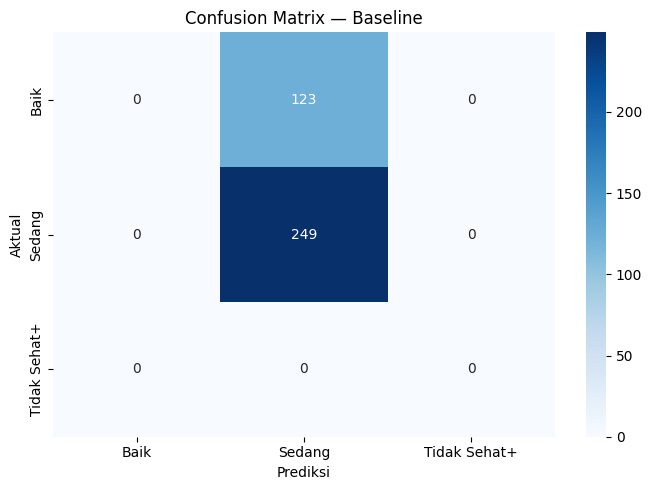

In [103]:
# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

labels = ["Baik", "Sedang", "Tidak Sehat+"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

,Feature,Importance
0,temperature_2m_24h,0.419642
1,wind_direction_sin_24h,0.171210
2,wind_direction_cos_24h,0.138652
3,wind_speed_10m_24h,0.077381
4,day_of_week,0.073128
5,precipitation_24h,0.057499
6,relative_humidity_2m_24h,0.045046
7,hour,0.015270
8,month,0.002172


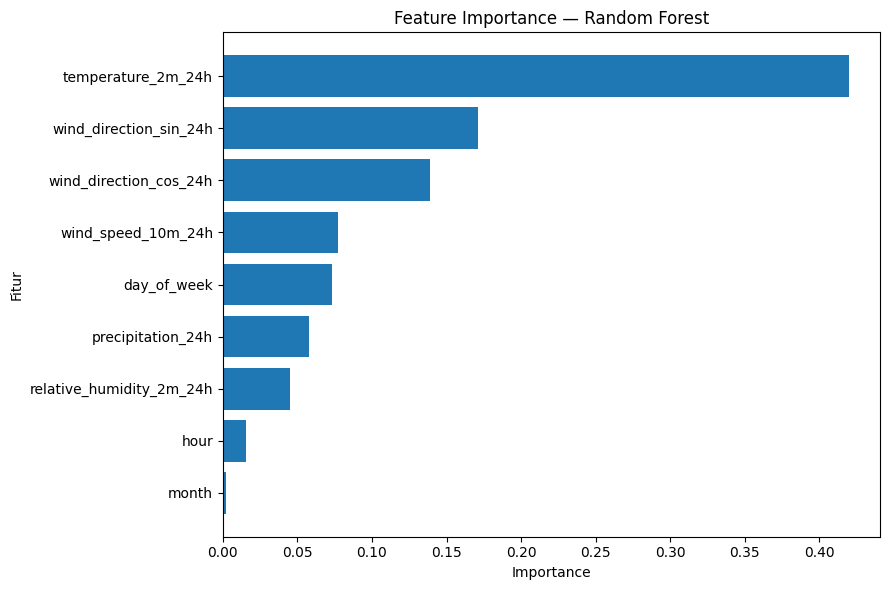

In [104]:
# ============================================================
# 15. FEATURE IMPORTANCE (JIKA MODEL TERBAIK RANDOM FOREST)
# ============================================================
# Feature importance hanya dihitung dari Random Forest yang sudah dilatih.

rf_model = fitted_models["Random Forest"]
feature_importance = (
    pd.DataFrame({
        "Feature": features,
        "Importance": rf_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance)

plt.figure(figsize=(9, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [105]:
# ============================================================
# 16. TABEL HASIL PREDIKSI
# ============================================================

prediction_results = test_data[
    ["location_id", "observed_at", "pm25", "pm25_24h", target]
].copy()
prediction_results["predicted_category"] = y_pred
prediction_results["correct_prediction"] = (
    prediction_results[target] == prediction_results["predicted_category"]
)

display(prediction_results.head(30))
print("\nAkurasi baris prediksi:", round(prediction_results["correct_prediction"].mean(), 4))

,location_id,observed_at,pm25,pm25_24h,quality_category,predicted_category,correct_prediction
1126,6536246,2026-10-01 21:00:00+00:00,4.6,30.375000,Sedang,Sedang,True
1127,6529627,2026-10-01 21:00:00+00:00,5.0,22.850000,Sedang,Sedang,True
1128,6494341,2026-10-01 21:00:00+00:00,104.4,49.500000,Sedang,Sedang,True
1129,6536246,2026-10-01 22:00:00+00:00,4.9,28.495833,Sedang,Sedang,True
1130,6529627,2026-10-01 22:00:00+00:00,5.9,20.150000,Sedang,Sedang,True
1131,6494341,2026-10-01 22:00:00+00:00,53.7,48.520833,Sedang,Sedang,True
1132,6536246,2026-10-01 23:00:00+00:00,7.3,26.662500,Sedang,Sedang,True
1133,6494341,2026-10-01 23:00:00+00:00,36.2,46.770833,Sedang,Sedang,True
1134,6529627,2026-10-01 23:00:00+00:00,4.7,18.079167,Sedang,Sedang,True
1135,6529627,2026-10-02 00:00:00+00:00,7.2,16.600000,Sedang,Sedang,True



Akurasi baris prediksi: 0.6694
